# Milestone 2 EDA: EIA-930 balance and interchange data, all 13 U.S. regions

**Canvas project group 100:** Allen Garcia, Amy Chen, Clara Cheng, Luke Tan, Sunny Li
**Notebook author:** Amy Chen

**What this notebook does.** It gets EIA's hourly grid data for every U.S. balancing authority, adds the balancing authorities up into EIA's **13 regions**, cleans the result, and does a first EDA:

1. Where the data comes from, how we got it, and its size
2. What one row and each column represent, including **which balancing authorities are in each region, and how that changed over time**
3. Cleaning, and the cleaned region table (saved as CSV)
4. Quick data-quality checks
5. EDA over the **full timeline** (2019 – Oct 2026): basic plots first, then polished charts. Each chart is drawn **for each region**, then **for all regions together**
6. EDA on the **focus period** the team chose: **2023 – Oct 2026** (post-COVID)
7. Summary of findings
8. Notes for joining with the team's other ERCOT data

PJM is the `MIDA` (Mid-Atlantic) region and ERCOT is the `TEX` (Texas) region: each is the only balancing authority in its region.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, ".")
import eia930 as E      # download / scan / clean / region table / carbon intensity
import style as S       # presentation style (same as the Allston energy & ICT project)
pd.set_option("display.width", 220, "display.max_columns", 40)

START, END = "2019-01-01", "2026-10-31"    # full window, local days, inclusive
FOCUS_START = "2023-01-01"                 # team decision: focus on the post-COVID period
RAW, OUT, FIG = "data/raw", "data", "figures"
os.makedirs(FIG, exist_ok=True)

RN = E.REGION_NAME                         # region code -> name
REGIONS = list(RN)                         # fixed order for every chart
PAL13 = dict(zip(REGIONS, sns.color_palette("tab20", 13)))   # one color per region in the basic plots


def grid13(sharex=True, sharey=False, figsize=(16, 13)):
    # 4 x 4 panels, one per region (3 left empty). Returns fig and {region: ax}
    fig, axes = plt.subplots(4, 4, figsize=figsize, sharex=sharex, sharey=sharey)
    axes = axes.ravel()
    for ax in axes[len(REGIONS):]:
        ax.axis("off")
    for ax in axes[:len(REGIONS)]:
        ax.xaxis.set_tick_params(labelbottom=True)
    return fig, dict(zip(REGIONS, axes))

## 1. Where the data comes from and how we got it

| | |
|---|---|
| **Source** | U.S. Energy Information Administration (EIA), *Form EIA-930 Hourly Electric Grid Monitor*: https://www.eia.gov/electricity/gridmonitor/ |
| **Files** | Public six-month bulk CSVs, no API key: `EIA930_BALANCE_{year}_{Jan_Jun or Jul_Dec}.csv` and `EIA930_INTERCHANGE_{...}.csv` from https://www.eia.gov/electricity/gridmonitor/sixMonthFiles/ |
| **BALANCE** | For every balancing authority (BA) and hour: demand, day-ahead demand forecast, net generation, total interchange, and net generation **by fuel** |
| **INTERCHANGE** | For every BA and hour: the flow to/from **each** directly connected neighbouring BA |
| **Downloaded** | 2026-11-11 |

The cell below downloads only the files that are not on disk yet.

In [2]:
bal_files = E.download(f"{RAW}/eia930", "BALANCE")
ix_files = E.download(f"{RAW}/eia930_interchange", "INTERCHANGE")

sizes = pd.DataFrame([{"kind": "BALANCE" if "BALANCE" in f else "INTERCHANGE", "file": os.path.basename(f),
                       "MB": os.path.getsize(f) / 1e6} for f in bal_files + ix_files])
print(sizes.groupby("kind").agg(files=("file", "count"), total_MB=("MB", "sum")).round(0))
print(f"\nTotal raw data: {sizes.MB.sum() / 1e3:.2f} GB")

             files  total_MB
kind                        
BALANCE         16     698.0
INTERCHANGE     16    1584.0

Total raw data: 2.28 GB


## 2. What one row and each column represent

### 2.1 BALANCE files, read exactly as published

**One row = one balancing authority × one hour.** We read **every column** of every file and let pandas infer the types, with no columns chosen or renamed first. The scan below also records which BAs and regions appear, and keeps a tidy copy for cleaning later. It takes about a minute.

In [3]:
B = E.scan_balance(bal_files)
tidy = B["tidy"]
print(f"rows (BA x hour):     {len(tidy):,}")
print(f"balancing authorities: {tidy.ba.nunique()}   regions: {tidy.region.nunique()}")
print(f"columns across all files: {len(B['profile'])}")

ncols = pd.Series({os.path.basename(f)[15:-4]: len(pd.read_csv(f, nrows=0).columns) for f in bal_files}, name="columns")
ncols.to_frame().T

rows (BA x hour):     4,301,471


balancing authorities: 69   regions: 13
columns across all files: 74


,2019_Jan_Jun,2019_Jul_Dec,2020_Jan_Jun,2020_Jul_Dec,2021_Jan_Jun,2021_Jul_Dec,2022_Jan_Jun,2022_Jul_Dec,2023_Jan_Jun,2023_Jul_Dec,2024_Jan_Jun,2024_Jul_Dec,2025_Jan_Jun,2025_Jul_Dec,2026_Jan_Jun,2026_Jul_Dec
columns,44,44,44,44,44,44,44,44,44,44,44,65,65,65,65,65


The files have **44 columns until June 2024 and 65 from July 2024**. In July 2024 EIA split solar, wind and hydro into sub-categories and added storage and geothermal. Across all files that is 74 different columns.

Every column, with the type pandas inferred, how many files have it, how full it is, and an example value:

In [4]:
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 50):
    display(B["profile"])

,dtype,files_with_column,% filled (where present),example
column,,,,
Balancing Authority,object,16,100.0,AEC
Data Date,object,16,100.0,01/01/2019
Hour Number,int64,16,100.0,1
Local Time at End of Hour,object,16,100.0,01/01/2019 1:00:00 AM
UTC Time at End of Hour,object,16,100.0,01/01/2019 7:00:00 AM
Demand Forecast (MW),float64,16,85.2,630.0
Demand (MW),float64,16,85.2,361.0
Net Generation (MW),float64,16,99.4,414.0
Total Interchange (MW),float64,16,99.4,53.0


**How to read the columns.** They come in a few families:

| Family | Columns | What they mean |
|---|---|---|
| **Identifiers / time** | `Balancing Authority`, `Region`, `Data Date`, `Hour Number`, `Local Time at End of Hour`, `UTC Time at End of Hour` | Which grid, which region, and which hour. `Hour Number` is 1–24 within the local day (23 or 25 on daylight-saving days). Times mark the **end** of the hour |
| **Totals** | `Demand Forecast (MW)`, `Demand (MW)`, `Net Generation (MW)`, `Total Interchange (MW)`, `Sum(Valid DIBAs) (MW)` | Day-ahead demand forecast, actual demand, total generation inside the BA, net flow out (+ = export), and the sum of flows reported per neighbour |
| **Generation by fuel** | `Net Generation (MW) from <fuel>` | MW from coal, gas, nuclear, oil, hydro, solar, wind, other, and (from Jul 2024) storage and geothermal |
| **`(Imputed)` versions** | e.g. `Demand (MW) (Imputed)` | Filled **only** in hours where EIA had to impute the value. Useful as a flag |
| **`(Adjusted)` versions** | e.g. `Demand (MW) (Adjusted)` | EIA's cleaned series: the reported value, or EIA's estimate where the reported one was missing or bad. **This is what we analyse** |

Things to notice:
- Every measurement column is read as a number (`float64`), and only the identifier and time columns are text (`object`). No types need to be forced.
- The `(Imputed)` columns are mostly empty, as they should be.
- Two of EIA's column names have typos (`Solar witho Integrated…`, and a double space in `Pumped Storage  (Adjusted)`). That matters when selecting columns by name.

### 2.2 Regions and balancing authorities

A **balancing authority (BA)** runs one grid area: it keeps supply and demand in balance there. Examples are PJM, ERCOT, CAISO, or a single utility like Duke Energy Carolinas. EIA groups BAs into **13 regions** (the `Region` column). Some regions are one big BA; others are many small utilities. Every BA stays in the same region in every year.

In [5]:
ba_info = B["ba_info"]
latest = B["ba_year"][B["ba_year"].year == 2026]
regions = (latest.groupby("Region")["Balancing Authority"]
           .agg(n_ba="nunique", balancing_authorities=lambda s: ", ".join(sorted(set(s))))
           .reindex(REGIONS))
regions.insert(0, "name", regions.index.map(RN))
print("BAs that ever change region:", int((B["ba_year"].groupby("Balancing Authority").Region.nunique() > 1).sum()))
with pd.option_context("display.max_colwidth", 200):
    display(regions)

BAs that ever change region: 0


,name,n_ba,balancing_authorities
Region,,,
CAL,California,5,"BANC, CISO, IID, LDWP, TIDC"
CAR,Carolinas,6,"CPLE, CPLW, DUK, SC, SCEG, YAD"
CENT,Central,2,"SPA, SWPP"
FLA,Florida,9,"FMPP, FPC, FPL, GVL, HST, JEA, SEC, TAL, TEC"
MIDA,Mid-Atlantic,1,PJM
MIDW,Midwest,4,"AECI, LGEE, MISO, SIKE"
NE,New England,1,ISNE
NW,Northwest,22,"AVA, AVRN, BHBA, BPAT, CHPD, DOPD, GCPD, GRID, GWA, IPCO, NEVP, NWMT, PACE, PACW, PGE, PSCO, PSEI, SCL, SWPW, TPWR, WACM, WAUW"
NY,New York,1,NYIS


In [6]:
# number of balancing authorities in each region, by year
ba_per_region_year = (B["ba_year"].groupby(["Region", "year"])["Balancing Authority"].nunique()
                      .unstack().reindex(REGIONS))
ba_per_region_year.loc["TOTAL"] = B["ba_year"].groupby("year")["Balancing Authority"].nunique()
ba_per_region_year

year,2019,2020,2021,2022,2023,2024,2025,2026
Region,,,,,,,,
CAL,5,5,5,5,5,5,5,5
CAR,6,6,6,6,6,6,6,6
CENT,2,2,2,2,2,2,2,2
FLA,10,10,9,9,9,9,9,9
MIDA,1,1,1,1,1,1,1,1
MIDW,4,5,4,4,3,3,4,4
NE,1,1,1,1,1,1,1,1
NW,21,21,21,21,21,21,21,22
NY,1,1,1,1,1,1,1,1


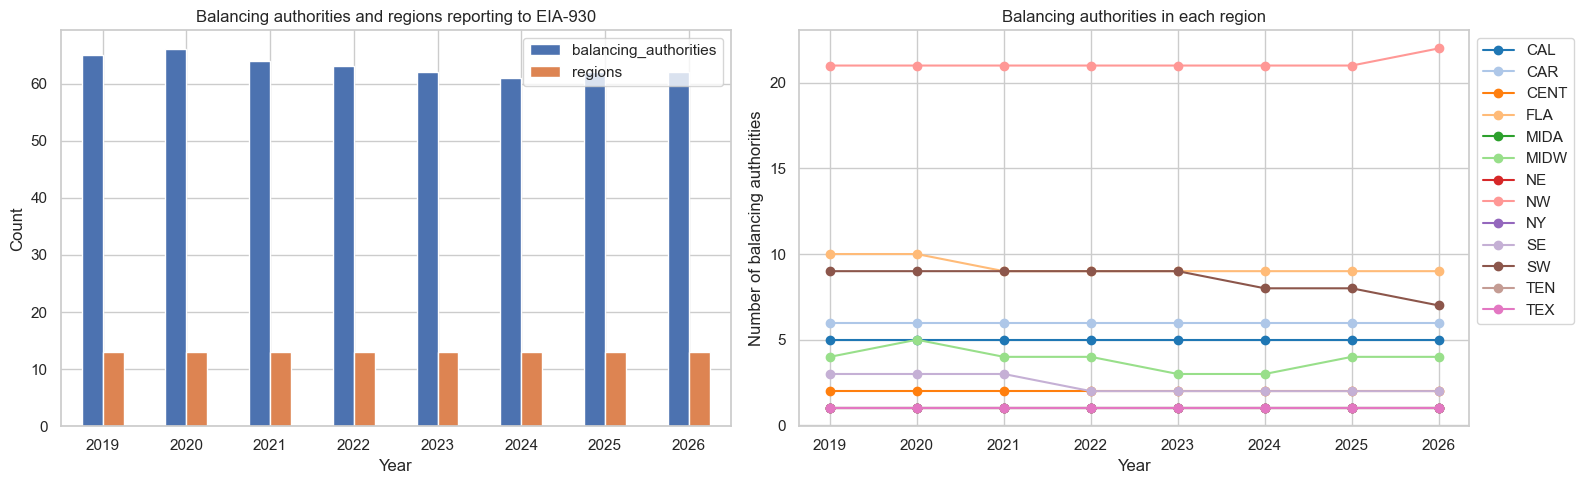

In [7]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# left: total BAs and regions per year
per_year = B["ba_year"].groupby("year").agg(balancing_authorities=("Balancing Authority", "nunique"),
                                            regions=("Region", "nunique"))
per_year.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_xlabel("Year"); axes[0].set_ylabel("Count")
axes[0].set_title("Balancing authorities and regions reporting to EIA-930")
# right: BAs per region, by year
ba_per_region_year.drop("TOTAL").T.plot(ax=axes[1], marker="o", color=[PAL13[r] for r in REGIONS])
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Number of balancing authorities")
axes[1].set_title("Balancing authorities in each region")
axes[1].legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
plt.show()

In [8]:
# which BAs started or stopped reporting during 2019 - Oct 2026?
came_went = ba_info[(ba_info.first_hour > "2019-01-02") | (ba_info.last_hour < "2026-10-01")].copy()
came_went["first_hour"] = came_went.first_hour.dt.date
came_went["last_hour"] = came_went.last_hour.dt.date
came_went.sort_values("region")

,region,first_hour,last_hour
ba,,,
NSB,FLA,2019-01-01,2020-01-08
EEI,MIDW,2019-01-01,2020-02-29
GLHB,MIDW,2020-02-29,2022-09-01
SIKE,MIDW,2025-06-01,2026-11-11
BHBA,NW,2026-04-01,2026-11-12
SWPW,NW,2026-04-01,2026-11-12
WACM,NW,2019-01-01,2026-04-01
WAUW,NW,2019-01-01,2026-04-01
WWA,NW,2019-01-01,2025-10-01


**What we see**

- **13 regions in every year.** The number of balancing authorities drifts from 65 (2019) to 62 (2026); 69 different BAs report at some point. No BA ever moves between regions.
- **Five regions are a single BA:** Mid-Atlantic (PJM), New England (ISO-NE), New York (NYISO), Tennessee (TVA) and Texas (ERCOT). The others group several BAs: the Northwest has 21–22, Florida 9–10, and the Southwest 7–9.
- **Changes over time are mostly small utilities.**
  - Retired: NSB (Florida) in Jan 2020, EEI (Midwest) in Feb 2020, AEC (Southeast) in Sep 2021, GRIF (Southwest) in Nov 2023, HGMA (Southwest) in Jun 2025, WWA (Northwest) in Oct 2025.
  - Came and went: GLHB (Midwest) reported only from Feb 2020 to Sep 2022.
  - New: SIKE (Midwest) from Jun 2025.
  - Biggest change: in the Northwest, WACM and WAUW stop on 1 Apr 2026, the same day BHBA and SWPW start.
- **Why it matters:** a region's total is the sum of whichever BAs report that hour (`n_ba` in the cleaned table). Because the BAs that come and go are small, region totals stay comparable over time.

### 2.3 Summary statistics, and impossible raw values

Summary statistics of the tidy BA-level table (the `(Adjusted)` series, all BAs pooled):

In [9]:
tidy.describe().T.round(0)

,count,mean,min,25%,50%,75%,max,std
utc_end,4301471,2022-11-15 12:13:37.651170048,2019-01-01 06:00:00,2020-11-25 14:00:00,2022-11-03 09:00:00,2024-10-31 23:00:00,2026-11-12 08:00:00,NaN
demand,3670841.0,8845.972656,0.0,763.0,2389.0,6250.0,224345.0,17875.722656
demand_fcst,3663942.0,8791.538086,-992136.0,783.0,2304.0,6116.0,466542.0,17974.548828
netgen,4284748.0,7489.47998,-398.0,501.0,1505.0,5351.0,164403.0,16916.662109
interchange,4274666.0,-40.316563,-17149.0,-486.0,-5.0,372.0,14985.0,1716.661621
coal,2450536.0,2526.237793,-73.0,137.0,637.0,2224.0,44915.0,5214.760254
gas,3497025.0,3578.65918,-10.0,316.0,793.0,2522.0,75926.0,7576.11084
nuclear,1229547.0,5047.195312,-10.0,1142.0,3339.0,5881.0,46004.0,6983.248535
oil,1442090.0,44.412128,-10.0,0.0,0.0,0.0,11841.0,207.868866
hydro,3127850.0,658.22345,-5798.0,22.0,189.0,727.0,14919.0,1346.311279


In [10]:
# raw values above 1,000,000 MW (impossible: the largest U.S. grid peaks around 160,000 MW)
bad = B["bad_raw"]
print(f"{len(bad)} impossible raw values in {bad.ba.nunique()} BAs")
display(bad.groupby(["ba", "column"]).size().rename("count").reset_index().sort_values("count", ascending=False).head(15))
bad.sort_values("value", ascending=False).head(5)

342 impossible raw values in 10 BAs


,ba,column,count
4,BANC,Demand (MW),92
8,BANC,Sum(Valid DIBAs) (MW),88
9,BANC,Total Interchange (MW),87
5,BANC,Net Generation (MW),12
7,BANC,Net Generation (MW) from Natural Gas,12
24,SWPP,Sum(Valid DIBAs) (MW),5
25,TVA,Demand (MW),3
14,PJM,Net Generation (MW),3
13,PJM,Demand (MW),3
11,LGEE,Demand (MW),3


,ba,column,utc_end,value
333,BANC,Net Generation (MW) from Hydropower Excluding ...,2026-01-22 20:00:00,2.576981e+09
311,PJM,Net Generation (MW),2021-10-19 04:00:00,2.147480e+09
307,PJM,Demand (MW),2021-10-19 04:00:00,2.147480e+09
306,PJM,Demand (MW),2021-10-19 03:00:00,1.527760e+09
310,PJM,Net Generation (MW),2021-10-19 03:00:00,1.527330e+09


These are broken records in the **raw** columns. Some are 2³¹ − 1 = 2,147,483,647, the largest 32-bit integer. We only use the `(Adjusted)` columns, where EIA has replaced them, so they don't enter the analysis. They're one more reason to use `(Adjusted)`.

### 2.4 INTERCHANGE files

**One row = one BA × one neighbouring BA × one hour.** `Interchange (MW)` > 0 means power flows **out** to that neighbour. The `Region` and `DIBA_Region` columns give both sides' regions. Neighbours include Canada (`CAN`) and Mexico (`MEX`).

In [11]:
ix_profile, flows = E.scan_interchange(ix_files)
display(ix_profile)
print(f"region-to-region flow table: {len(flows):,} rows (region x neighbouring region x hour)")
flows.head()

,dtype,files_with_column,% filled (where present),example
column,,,,
Balancing Authority,object,16,100.0,AEC
Data Date,object,16,100.0,1/1/19
Hour Number,int64,16,100.0,1
Directly Interconnected Balancing Authority,object,16,100.0,MISO
Interchange (MW),float64,16,98.8,28.0
Local Time at End of Hour,object,16,100.0,1/1/19 1:00
UTC Time at End of Hour,object,16,100.0,1/1/19 7:00
Region,object,16,100.0,SE
DIBA_Region,object,16,100.0,MIDW


region-to-region flow table: 2,920,531 rows (region x neighbouring region x hour)


,region,to_region,utc_end,mw
0,CAL,MEX,2019-01-01 09:00:00,-35.0
1,CAL,MEX,2019-01-01 10:00:00,-45.0
2,CAL,MEX,2019-01-01 11:00:00,-78.0
3,CAL,MEX,2019-01-01 12:00:00,-107.0
4,CAL,MEX,2019-01-01 13:00:00,-130.0


## 3. Cleaning, and the cleaned region table

`E.build_regions` does the following (code in `eia930.py`):

1. **Harmonize the fuels.** The `(Adjusted)` fuel columns are mapped onto 8 fuels that mean the same in every year: coal, gas, nuclear, oil, hydro, solar, wind, other. After July 2024, hydro, solar and wind are the sums of their new sub-categories. Geothermal and battery storage are added to **other**, where EIA counted them before July 2024. Battery charging (negative) counts as 0.
2. **Clean each BA.** One-hour spikes and impossible values (e.g. PJM nuclear at 46 GW, above its ~33 GW capacity) are set to missing. Gaps of ≤ 3 h are filled by time interpolation.
3. **Add BAs up into regions.** Demand, forecast, generation, interchange and each fuel are summed over the region's BAs for each hour. `n_ba` records how many BAs reported that hour.
4. **Local clock per region.** UTC is converted to one time zone per region (table below). `hour` is the local hour *beginning* (0 = midnight–1 am).
5. **Carbon intensity** (kg CO₂/MWh, production-based) = Σ(generation by fuel × emission factor) / Σ generation. The emission factor is EIA's CO₂ coefficient × that year's national heat rate: coal ≈ 1,030, gas ≈ 410, oil ≈ 830 kg/MWh, everything else 0. If the fuels add up to less than 85% of reported net generation, part of the mix is missing, so carbon intensity is left blank.

In [12]:
pd.DataFrame({"name": RN, "time zone used": E.REGION_TZ})

,name,time zone used
CAL,California,America/Los_Angeles
CAR,Carolinas,America/New_York
CENT,Central,America/Chicago
FLA,Florida,America/New_York
MIDA,Mid-Atlantic,America/New_York
MIDW,Midwest,America/Chicago
NE,New England,America/New_York
NW,Northwest,America/Los_Angeles
NY,New York,America/New_York
SE,Southeast,America/Chicago


In [13]:
R, cleaned = E.build_regions(tidy, START, END)
R["region_name"] = R.region.map(RN)
print("cleaned region table:", R.shape[0], "rows x", R.shape[1], "columns")
print("rows per region:", R.groupby("region").size().iloc[0], "(one per hour, Jan 2019 – Oct 2026)")
R.head()

cleaned region table: 892620 rows x 25 columns
rows per region: 68663 (one per hour, Jan 2019 – Oct 2026)


,region,utc_end,date,hour,year,month,dow,season,n_ba,demand,demand_fcst,netgen,interchange,coal,gas,nuclear,oil,hydro,solar,wind,other,co2_t,ci,mix_ratio,region_name
0,CAL,2019-01-01 09:00:00,2019-01-01,0,2019,1,1,Winter,5,26876.0,26940.0,18423.0,-6631.0,1778.0,8627.0,2273.0,89.0,2295.0,-22.0,2604.0,779.0,5400.788574,292.805023,1.001194,California
1,CAL,2019-01-01 10:00:00,2019-01-01,1,2019,1,1,Winter,5,25989.0,25922.0,17616.0,-6439.0,1765.0,8259.0,2275.0,89.0,2002.0,-22.0,2514.0,731.0,5237.209961,296.978180,1.001079,California
2,CAL,2019-01-01 11:00:00,2019-01-01,2,2019,1,1,Winter,5,25295.0,25159.0,17241.0,-6254.0,1743.0,8168.0,2274.0,88.0,1724.0,-25.0,2539.0,724.0,5176.903320,299.936462,1.001102,California
3,CAL,2019-01-01 12:00:00,2019-01-01,3,2019,1,1,Winter,5,24884.0,24700.0,17153.0,-6225.0,1727.0,8134.0,2273.0,90.0,1757.0,-25.0,2464.0,727.0,5148.463379,299.817352,1.001108,California
4,CAL,2019-01-01 13:00:00,2019-01-01,4,2019,1,1,Winter,5,24922.0,24699.0,17557.0,-6177.0,1747.0,8473.0,2275.0,91.0,1962.0,-26.0,2280.0,751.0,5308.109375,301.957428,1.001253,California


In [14]:
# one row = one region in one hour. Example: Mid-Atlantic (PJM), 15 Jul 2025, 2-3 pm local
R[(R.region == "MIDA") & (R.date == "2025-07-15") & (R.hour == 14)].T

,331953
region,MIDA
utc_end,2025-07-15 19:00:00
date,2025-07-15 00:00:00
hour,14
year,2025
month,7
dow,1
season,Summer
n_ba,1
demand,137398.0


| Column | Units | Meaning |
|---|---|---|
| `region`, `region_name` | | EIA region code and name |
| `utc_end` | UTC | **End** of the hour. Use this as the join key |
| `date`, `hour` | local | Local day and hour *beginning* (0–23), on the region's clock |
| `year`, `month`, `dow`, `season` | | Calendar fields from `date` (`dow` 0 = Monday) |
| `n_ba` | count | Number of balancing authorities summed into this hour |
| `demand` | MW | Actual demand |
| `demand_fcst` | MW | Day-ahead demand forecast (known before the day starts) |
| `netgen` | MW | Total generation inside the region |
| `interchange` | MW | Net flow out of the region's BAs: > 0 = net **exports** |
| `coal` … `other` | MW | Generation by fuel (8 fuels) |
| `co2_t` | t CO₂ | CO₂ from the region's own generation that hour |
| `ci` | kg CO₂/MWh | **Carbon intensity**, the project's target |
| `mix_ratio` | | Fuels ÷ net generation; carbon intensity is blank when below 0.85 |

In [15]:
R.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 892620 entries, 0 to 892619
Data columns (total 25 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   region       892620 non-null  object        
 1   utc_end      892620 non-null  datetime64[ns]
 2   date         892620 non-null  datetime64[ns]
 3   hour         892620 non-null  int32         
 4   year         892620 non-null  int32         
 5   month        892620 non-null  int32         
 6   dow          892620 non-null  int32         
 7   season       892620 non-null  object        
 8   n_ba         892620 non-null  int64         
 9   demand       892596 non-null  float32       
 10  demand_fcst  892132 non-null  float32       
 11  netgen       892593 non-null  float32       
 12  interchange  892362 non-null  float32       
 13  coal         884344 non-null  float32       
 14  gas          892590 non-null  float32       
 15  nuclear      892539 non-null  floa

In [16]:
# mean of the main columns by region
R.groupby("region_name")[["n_ba", "demand", "netgen", "interchange", "co2_t", "ci"]].mean().round(0).sort_values("demand", ascending=False)

,n_ba,demand,netgen,interchange,co2_t,ci
region_name,,,,,,
Mid-Atlantic,1.0,92414.0,96087.0,3519.0,34305.0,353.0
Midwest,4.0,80967.0,78365.0,-4128.0,39184.0,496.0
Texas,1.0,49836.0,49747.0,-89.0,16764.0,335.0
Northwest,21.0,40610.0,42322.0,5036.0,13347.0,316.0
Central,2.0,32307.0,33254.0,942.0,13479.0,398.0
California,5.0,30976.0,24005.0,-5779.0,5004.0,209.0
Florida,9.0,29399.0,28780.0,-479.0,10296.0,357.0
Southeast,2.0,27271.0,28444.0,1030.0,11318.0,394.0
Carolinas,6.0,25495.0,25258.0,-305.0,7816.0,297.0


In [17]:
# how many values the cleaning step replaced, per BA (top 10)
cleaned.assign(total=cleaned.sum(axis=1)).sort_values("total", ascending=False).head(10)

,coal,gas,nuclear,oil,hydro,solar,wind,other,demand,demand_fcst,total
PJM,279,157,700,193,96,61,1039,99,11,0,2635
SPA,0,0,0,0,5,0,0,0,0,1954,1959
NYIS,0,10,12,540,2,0,1,495,12,185,1257
ERCO,10,3,6,0,0,116,3,599,0,3,740
NEVP,122,325,0,0,0,51,1,147,40,9,695
AZPS,8,25,1,0,0,14,15,280,41,265,649
MISO,1,0,2,0,436,127,4,67,1,0,638
WACM,70,19,0,0,97,13,26,0,128,131,484
SEC,52,72,0,0,0,1,0,0,271,0,396
WALC,0,8,0,0,10,35,2,0,68,244,367


**Saving the cleaned data as CSV.** The full region table is ~136 MB as a plain CSV, above GitHub's 100 MB file limit. So the repository gets a **gzipped CSV** (`.csv.gz`, ~36 MB), which `pd.read_csv` opens directly. A plain `.csv` is also written for opening in Excel, but it stays on your computer (it is gitignored).

In [18]:
out = R.drop(columns="region_name").copy()
out["date"] = out.date.dt.date
num_cols = out.select_dtypes("float32").columns
out[num_cols] = out[num_cols].round(1)
out["mix_ratio"] = R.mix_ratio.round(3)

out.to_csv(f"{OUT}/regions_hourly_clean.csv.gz", index=False)      # in the repo
out.to_csv(f"{OUT}/regions_hourly_clean.csv", index=False)         # local only (too big for GitHub)
flows.round(1).to_csv(f"{OUT}/region_flows_hourly.csv.gz", index=False)
ba_info.join(B["ba_year"].pivot_table(index="Balancing Authority", columns="year", values="hours", aggfunc="sum")
             .add_prefix("hours_")).to_csv(f"{OUT}/balancing_authorities.csv")
for f in ["regions_hourly_clean.csv.gz", "regions_hourly_clean.csv", "region_flows_hourly.csv.gz", "balancing_authorities.csv"]:
    print(f"saved data/{f:30s} {os.path.getsize(f'{OUT}/{f}') / 1e6:6.1f} MB")

saved data/regions_hourly_clean.csv.gz      36.7 MB
saved data/regions_hourly_clean.csv        136.8 MB
saved data/region_flows_hourly.csv.gz       13.8 MB
saved data/balancing_authorities.csv         0.0 MB


## 4. Quick data-quality checks

In [19]:
num = ["demand", "demand_fcst", "netgen", "interchange", *E.FUELS, "co2_t", "ci"]
print("% of hours missing, by region:")
R[num].isna().groupby(R.region_name).mean().mul(100).round(2)

% of hours missing, by region:


,demand,demand_fcst,netgen,interchange,coal,gas,nuclear,oil,hydro,solar,wind,other,co2_t,ci
region_name,,,,,,,,,,,,,,
California,0.00,0.00,0.00,0.00,0.00,0.00,0.03,0.03,0.00,0.00,0.00,0.00,0.00,0.00
Carolinas,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00
Central,0.00,0.03,0.00,0.00,0.00,0.00,0.02,0.00,0.00,0.00,0.00,0.00,0.01,0.01
Florida,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.03,0.03
Mid-Atlantic,0.00,0.30,0.00,0.28,0.00,0.00,0.04,0.00,0.00,0.00,0.00,0.00,1.08,1.08
Midwest,0.00,0.00,0.00,0.00,0.00,0.00,0.00,56.24,0.00,0.00,0.00,0.00,0.00,0.00
New England,0.00,0.00,0.00,0.01,12.02,0.01,0.00,7.21,0.00,0.00,0.00,0.00,0.01,0.01
New York,0.00,0.23,0.00,0.00,0.00,0.01,0.00,0.04,0.00,0.00,0.00,0.03,0.03,0.03
Northwest,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01


In [20]:
print("% of hours with no carbon intensity, by region and year:")
R.ci.isna().groupby([R.region_name, R.year]).mean().mul(100).round(2).unstack()

% of hours with no carbon intensity, by region and year:


year,2019,2020,2021,2022,2023,2024,2025,2026
region_name,,,,,,,,
California,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.03
Carolinas,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Central,0.06,0.00,0.00,0.00,0.00,0.01,0.00,0.00
Florida,0.02,0.03,0.05,0.06,0.06,0.03,0.00,0.00
Mid-Atlantic,0.00,8.11,0.03,0.18,0.11,0.00,0.00,0.00
Midwest,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
New England,0.00,0.08,0.00,0.00,0.00,0.00,0.00,0.03
New York,0.05,0.01,0.00,0.02,0.00,0.02,0.05,0.10
Northwest,0.00,0.00,0.00,0.00,0.00,0.00,0.11,0.00


In [21]:
# does the region's total interchange (BALANCE) match the sum of its flows to other regions (INTERCHANGE)?
s = flows.groupby(["region", "utc_end"]).mw.sum(min_count=1).rename("sum_of_flows").reset_index()
chk = R.merge(s, on=["region", "utc_end"])
print("correlation (sum of region-to-region flows, total interchange), by region and year:")
chk.groupby(["region_name", "year"])[["sum_of_flows", "interchange"]].corr().xs("sum_of_flows", level=2)["interchange"].unstack().round(2)

correlation (sum of region-to-region flows, total interchange), by region and year:


year,2019,2020,2021,2022,2023,2024,2025,2026
region_name,,,,,,,,
California,0.99,0.99,0.99,1.00,0.99,0.76,0.98,0.99
Carolinas,0.91,0.91,1.00,1.00,0.99,0.99,0.98,0.97
Central,0.67,-0.01,0.94,0.97,0.99,0.90,0.65,0.03
Florida,0.97,0.95,0.96,0.99,0.96,0.96,0.93,0.92
Mid-Atlantic,-0.64,0.75,0.81,0.82,0.83,0.79,0.62,0.45
Midwest,0.99,0.99,1.00,1.00,1.00,0.99,1.00,1.00
New England,1.00,1.00,0.97,1.00,1.00,1.00,1.00,1.00
New York,0.99,0.99,1.00,1.00,1.00,1.00,0.99,1.00
Northwest,0.96,0.83,0.96,0.96,0.98,0.98,0.84,0.97


**What the checks say**

- **Very little is missing.** Under 0.4% of hours for any measured column in any region. The "100% missing" cells are fuels a region doesn't report (no wind in the Carolinas or Florida, no oil in Texas), not missing data.
- **Carbon intensity is blank in very few hours.** The exception is the Mid-Atlantic in 2020 (8%), where PJM's January 2020 fuel mix is broken.
- **Interchange mostly adds up.** For most regions, the sum of region-to-region flows matches the reported total interchange (correlation ≥ 0.9). The exceptions are the Mid-Atlantic in 2019 (flows run *opposite* to the total), the Central region in 2020 and 2026, and the Southeast and Southwest in 2019–2020. Use flows from those years with care.
- **⚠️ California 2026 needs checking.** CAISO's reported gas generation falls from 6–15 GW (Mar–Jul 2025) to 1.6–3.3 GW (Mar–Jul 2026), then returns to normal in August. That looks more like a reporting change than real grid behaviour. Check California's 2026 numbers against CAISO's own data before relying on them.

## 5. EDA: full timeline (Jan 2019 – Oct 2026)

### 5.0 Basic EDA first

Standard first-look plots with plain pandas / seaborn. Each one is drawn **for each region** (a 4 × 4 grid of panels), then **for all regions together**.

In [22]:
plt.rcdefaults()
sns.set_theme(style="whitegrid")   # plain default plots for this block

#### (a) Distribution of carbon intensity

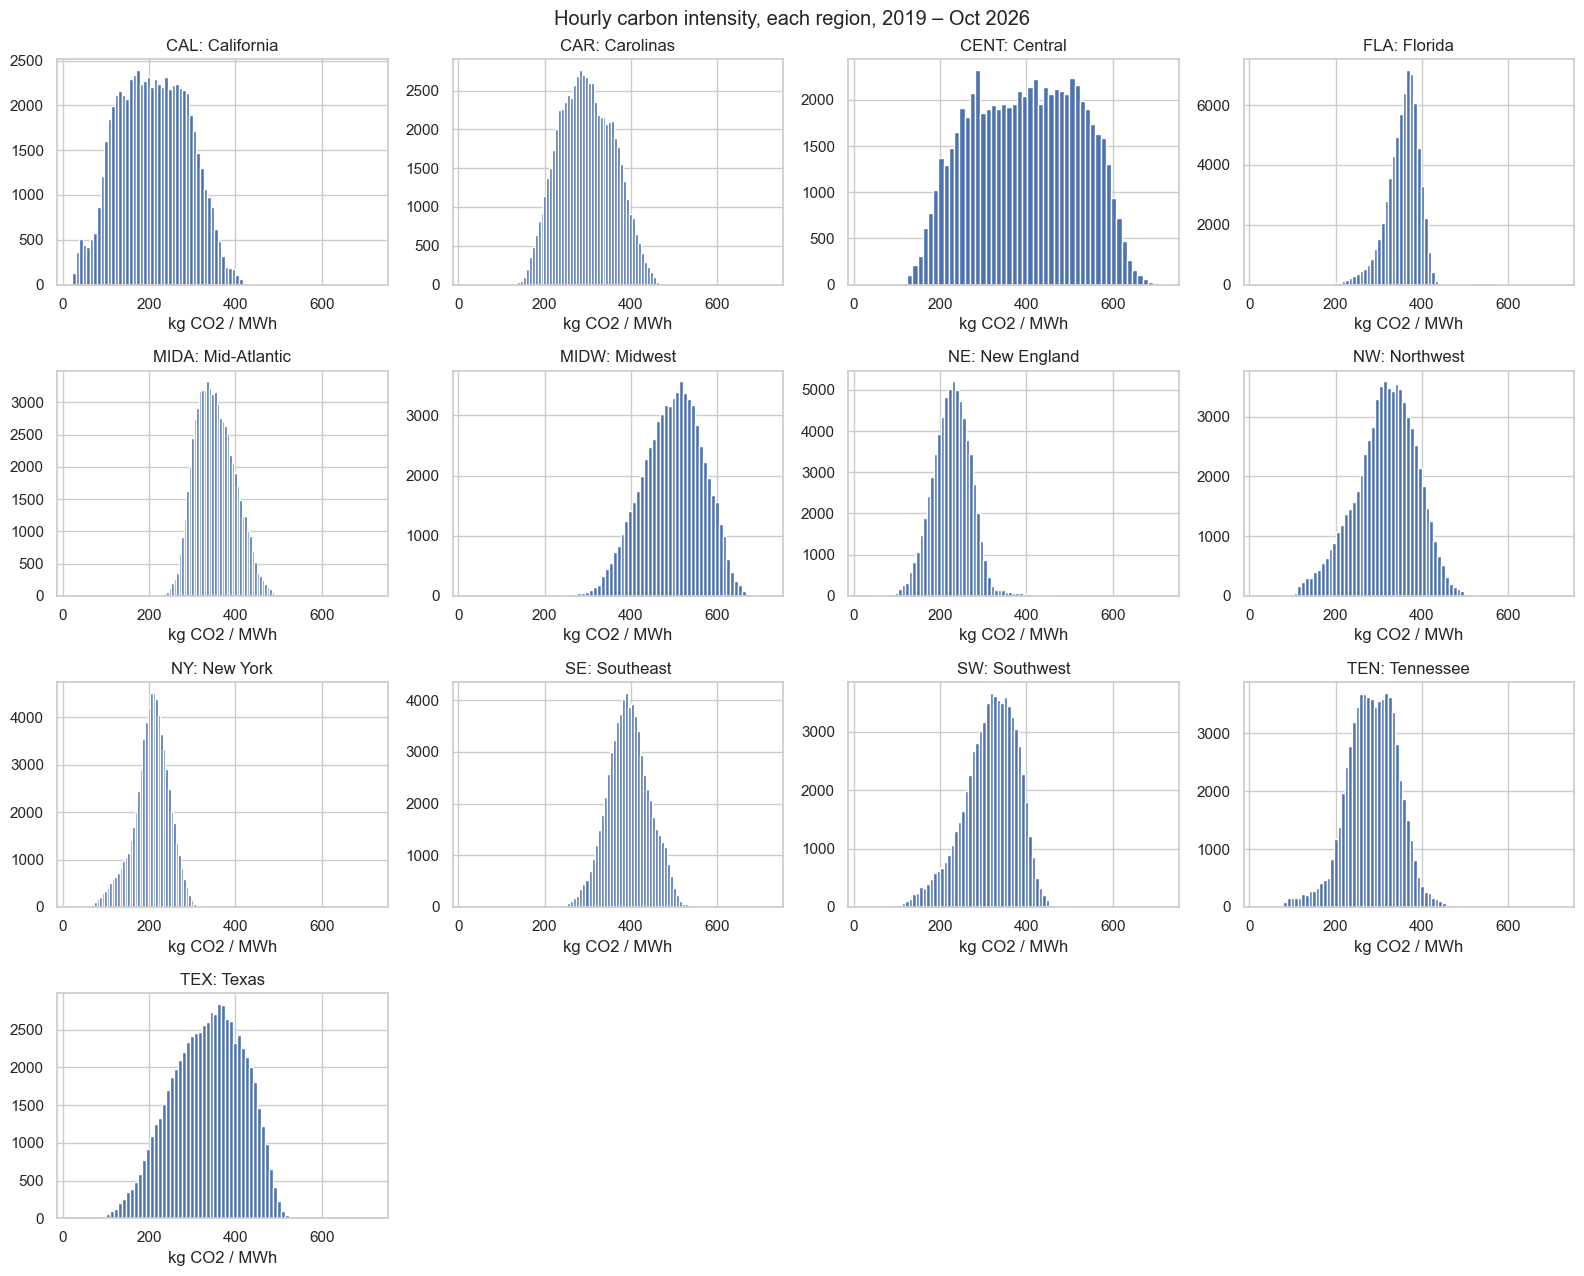

In [23]:
fig, ax = grid13()
for r in REGIONS:
    ax[r].hist(R.loc[R.region == r, "ci"].dropna(), bins=50, color="C0")
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("kg CO2 / MWh")
plt.suptitle("Hourly carbon intensity, each region, 2019 – Oct 2026")
plt.tight_layout()
plt.show()

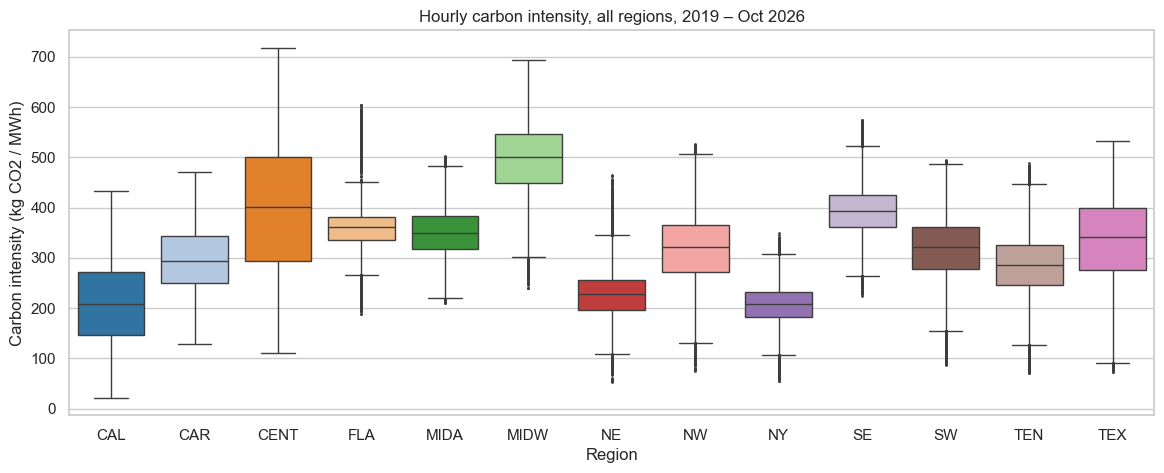

,count,mean,std,min,25%,50%,75%,max
region_name,,,,,,,,
New York,68643.0,205.0,41.0,55.0,182.0,208.0,232.0,350.0
California,68660.0,209.0,80.0,22.0,146.0,208.0,271.0,433.0
New England,68654.0,227.0,45.0,54.0,197.0,228.0,257.0,465.0
Tennessee,68659.0,284.0,59.0,71.0,246.0,286.0,326.0,489.0
Carolinas,68663.0,297.0,63.0,129.0,249.0,294.0,344.0,471.0
Northwest,68653.0,316.0,71.0,76.0,272.0,321.0,366.0,525.0
Southwest,68634.0,316.0,62.0,87.0,279.0,322.0,362.0,494.0
Texas,68627.0,335.0,82.0,73.0,276.0,341.0,399.0,533.0
Mid-Atlantic,67922.0,353.0,46.0,210.0,318.0,349.0,384.0,502.0


In [24]:
# all together
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=R, x="region", y="ci", order=REGIONS, palette=PAL13, hue="region", legend=False, fliersize=1, ax=ax)
ax.set_xlabel("Region")
ax.set_ylabel("Carbon intensity (kg CO2 / MWh)")
ax.set_title("Hourly carbon intensity, all regions, 2019 – Oct 2026")
plt.show()

R.groupby("region_name").ci.describe().round(0).sort_values("mean")

#### (b) Energy mix

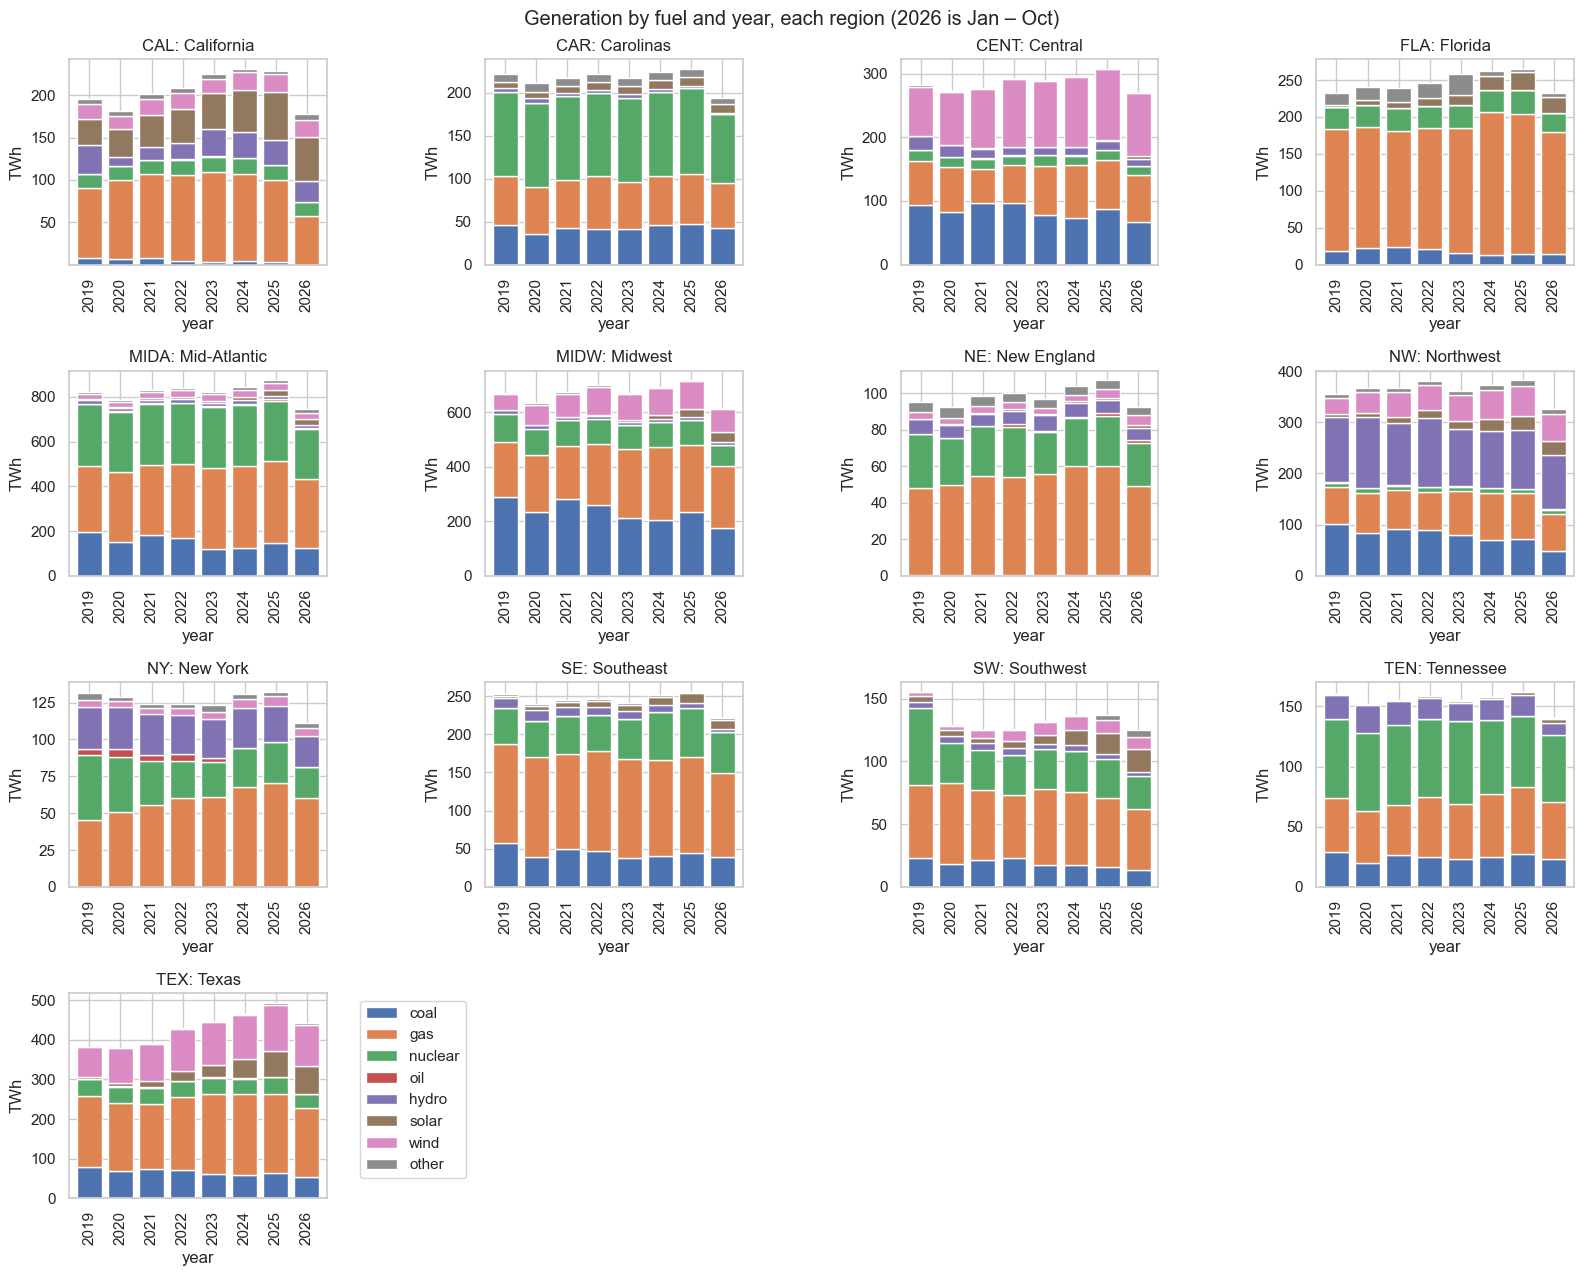

In [25]:
fig, ax = grid13(sharex=False)
for r in REGIONS:
    yearly_mix = R[R.region == r].groupby("year")[E.FUELS].sum() / 1e6     # MWh -> TWh
    yearly_mix.plot(kind="bar", stacked=True, ax=ax[r], legend=False, rot=90, width=0.8)
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_ylabel("TWh")
ax["TEX"].legend(bbox_to_anchor=(1.1, 1))
plt.suptitle("Generation by fuel and year, each region (2026 is Jan – Oct)")
plt.tight_layout()
plt.show()

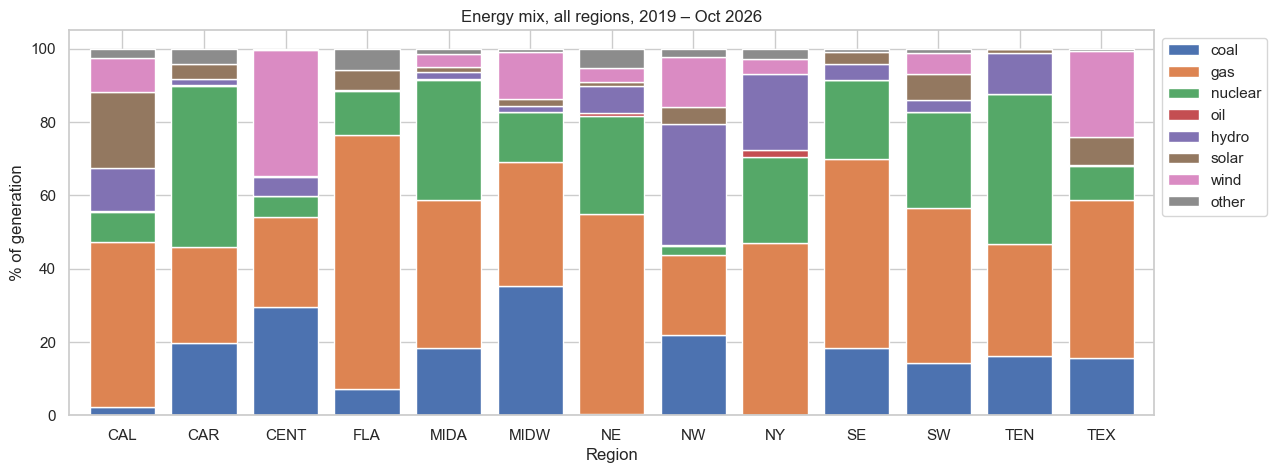

,coal,gas,nuclear,oil,hydro,solar,wind,other
region,,,,,,,,
CAL,2.200000,45.000000,8.300000,0.3,11.800000,20.799999,9.000000,2.7
CAR,19.700001,26.200001,44.099998,0.0,1.800000,4.100000,0.000000,4.2
CENT,29.600000,24.600000,5.500000,0.0,5.100000,0.500000,34.200001,0.5
FLA,7.200000,69.300003,12.100000,0.0,0.100000,5.400000,0.000000,5.9
MIDA,18.400000,40.400002,32.500000,0.4,1.900000,1.400000,3.400000,1.5
MIDW,35.200001,34.000000,13.600000,0.0,1.600000,1.800000,13.000000,0.8
NE,0.300000,54.599998,26.700001,0.8,7.500000,1.000000,4.000000,5.2
NW,21.799999,22.000000,2.400000,0.1,33.200001,4.600000,13.500000,2.4
NY,0.000000,46.900002,23.400000,2.1,20.700001,0.000000,4.000000,2.8


In [26]:
# all together: % of generation by fuel, whole period
mix = R.groupby("region")[E.FUELS].sum().reindex(REGIONS)
mix = mix.div(mix.sum(axis=1), axis=0) * 100
mix.plot(kind="bar", stacked=True, figsize=(14, 5), rot=0, width=0.8)
plt.xlabel("Region")
plt.ylabel("% of generation")
plt.title("Energy mix, all regions, 2019 – Oct 2026")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()
mix.round(1)

#### (c) Carbon emissions by hour of day

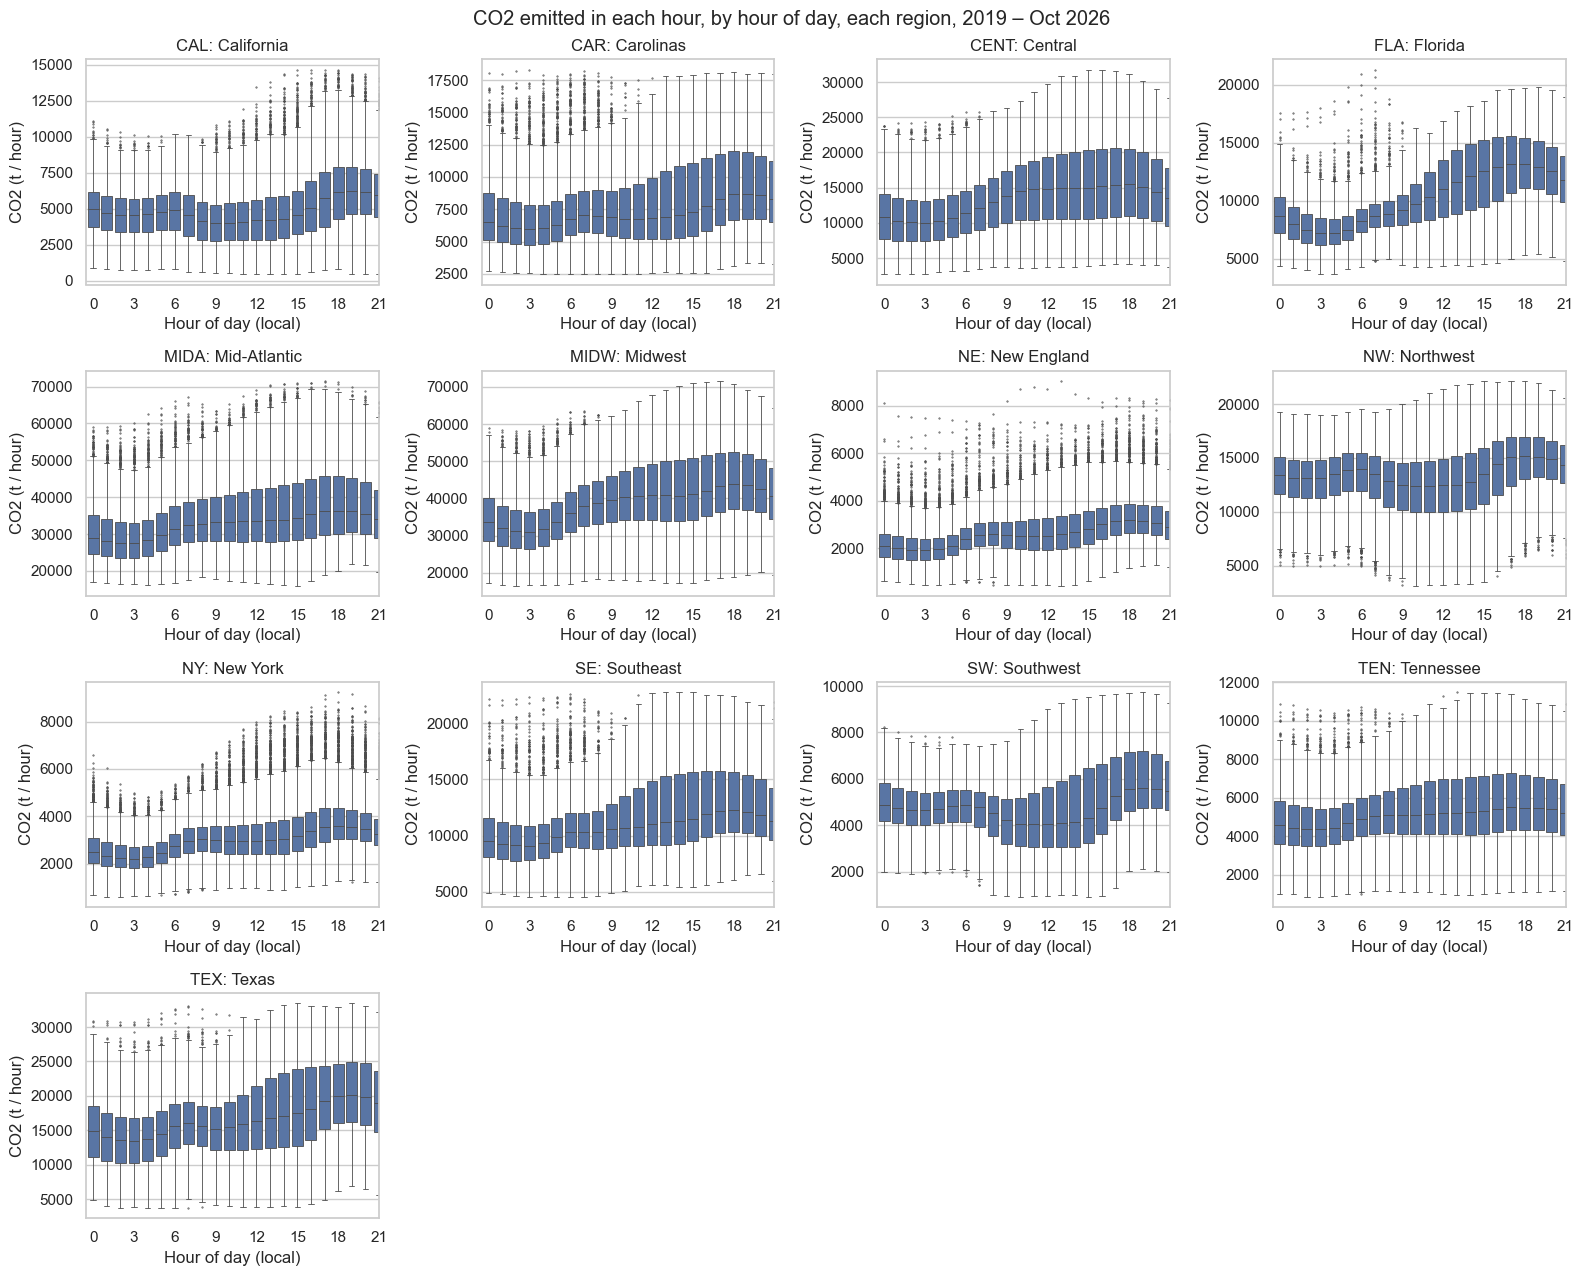

In [27]:
fig, ax = grid13()
for r in REGIONS:
    sns.boxplot(data=R[R.region == r], x="hour", y="co2_t", color="C0", fliersize=0.5, linewidth=0.6, ax=ax[r])
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("Hour of day (local)")
    ax[r].set_ylabel("CO2 (t / hour)")
    ax[r].set_xticks(range(0, 24, 3))
plt.suptitle("CO2 emitted in each hour, by hour of day, each region, 2019 – Oct 2026")
plt.tight_layout()
plt.show()

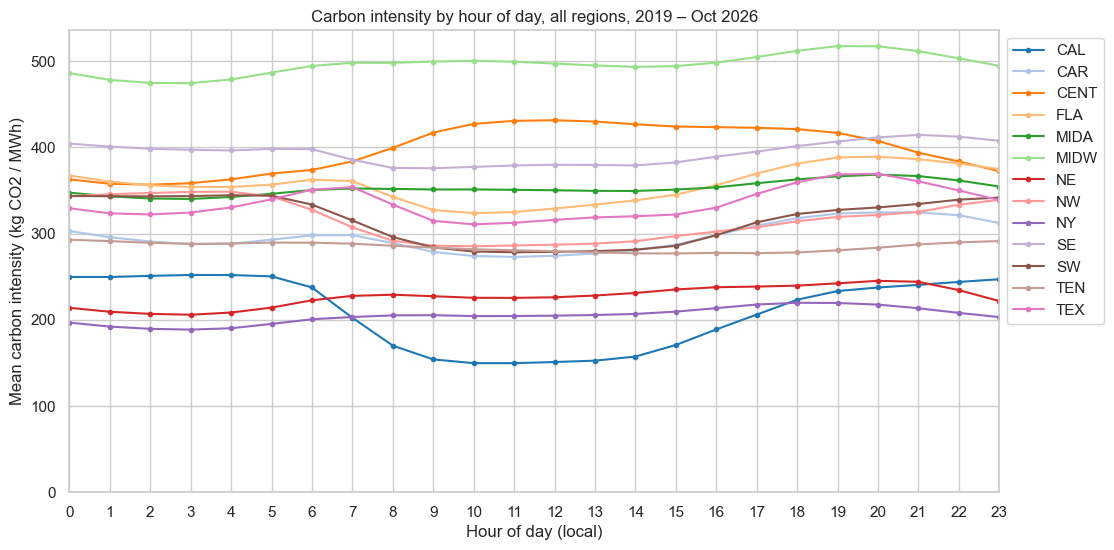

In [28]:
# all together: mean carbon intensity (per MWh, so regions of different size are comparable) by hour of day
by_hour = R.groupby(["hour", "region"]).ci.mean().unstack()[REGIONS]
by_hour.plot(figsize=(12, 6), marker="o", ms=3, color=[PAL13[r] for r in REGIONS])
plt.xlabel("Hour of day (local)")
plt.ylabel("Mean carbon intensity (kg CO2 / MWh)")
plt.title("Carbon intensity by hour of day, all regions, 2019 – Oct 2026")
plt.legend(bbox_to_anchor=(1, 1))
plt.xticks(range(24))
plt.xlim(0, 23)      # hour 0 sits on the y-axis, no padding
plt.ylim(bottom=0)   # 0 = carbon-free power, so the gap between regions is shown at true size
plt.show()

#### (d) Carbon intensity by year

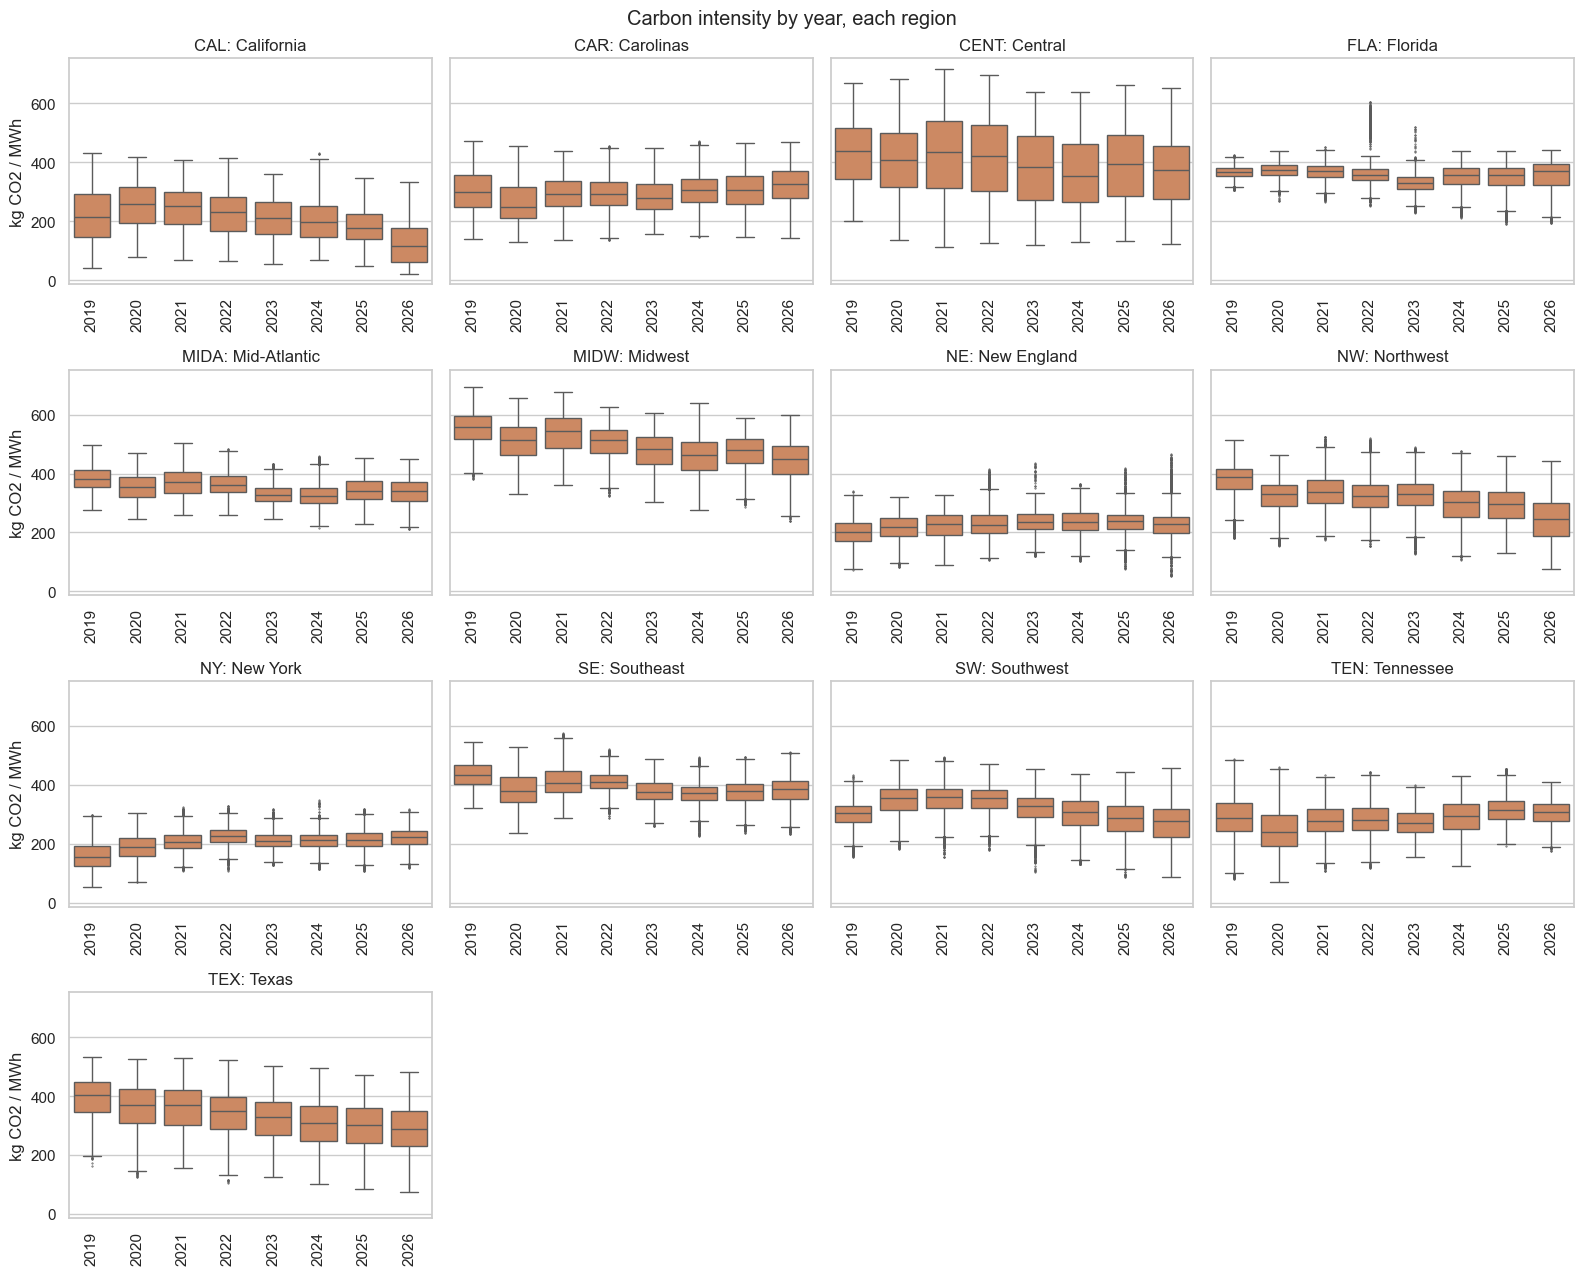

In [29]:
fig, ax = grid13(sharey=True)
for r in REGIONS:
    sns.boxplot(data=R[R.region == r], x="year", y="ci", color="C1", fliersize=0.5, ax=ax[r])
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("")
    ax[r].set_ylabel("kg CO2 / MWh")
    ax[r].tick_params(axis="x", rotation=90)
plt.suptitle("Carbon intensity by year, each region")
plt.tight_layout()
plt.show()

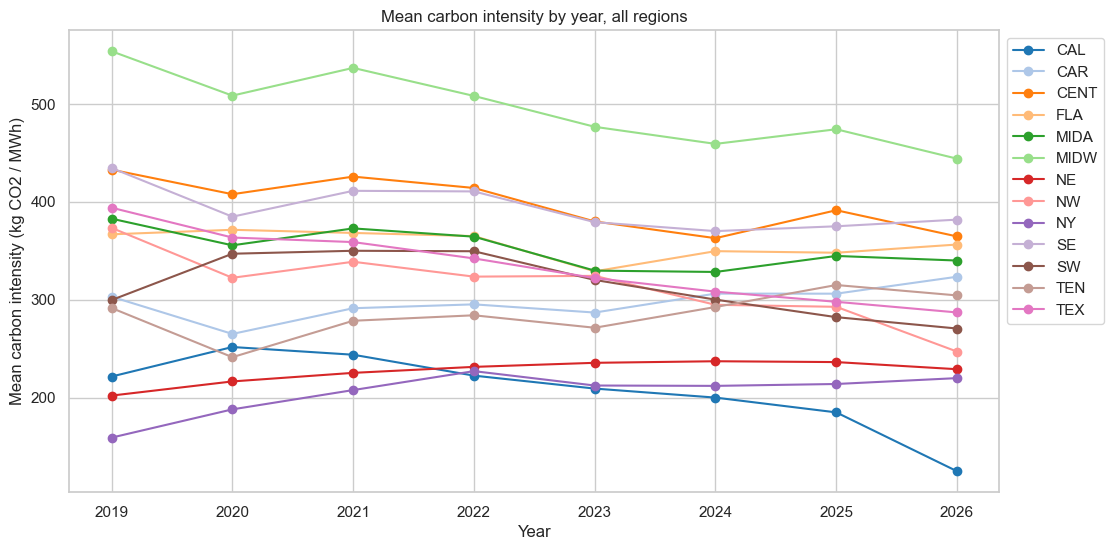

year,2019,2020,2021,2022,2023,2024,2025,2026
region,,,,,,,,
CAL,222.0,252.0,244.0,223.0,209.0,200.0,185.0,125.0
CAR,303.0,265.0,291.0,295.0,287.0,306.0,306.0,324.0
CENT,433.0,408.0,426.0,414.0,380.0,363.0,391.0,365.0
FLA,367.0,371.0,368.0,365.0,329.0,350.0,348.0,356.0
MIDA,383.0,356.0,373.0,364.0,330.0,328.0,345.0,340.0
MIDW,554.0,508.0,537.0,508.0,477.0,459.0,474.0,444.0
NE,202.0,217.0,225.0,232.0,236.0,237.0,236.0,229.0
NW,373.0,322.0,339.0,324.0,324.0,295.0,293.0,247.0
NY,159.0,188.0,208.0,227.0,212.0,212.0,214.0,220.0


In [30]:
# all together
yearly_ci = R.groupby(["year", "region"]).ci.mean().unstack()[REGIONS]
yearly_ci.plot(figsize=(12, 6), marker="o", color=[PAL13[r] for r in REGIONS])
plt.xlabel("Year")
plt.ylabel("Mean carbon intensity (kg CO2 / MWh)")
plt.title("Mean carbon intensity by year, all regions")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()
yearly_ci.T.round(0)

#### (e) Daily carbon intensity over time

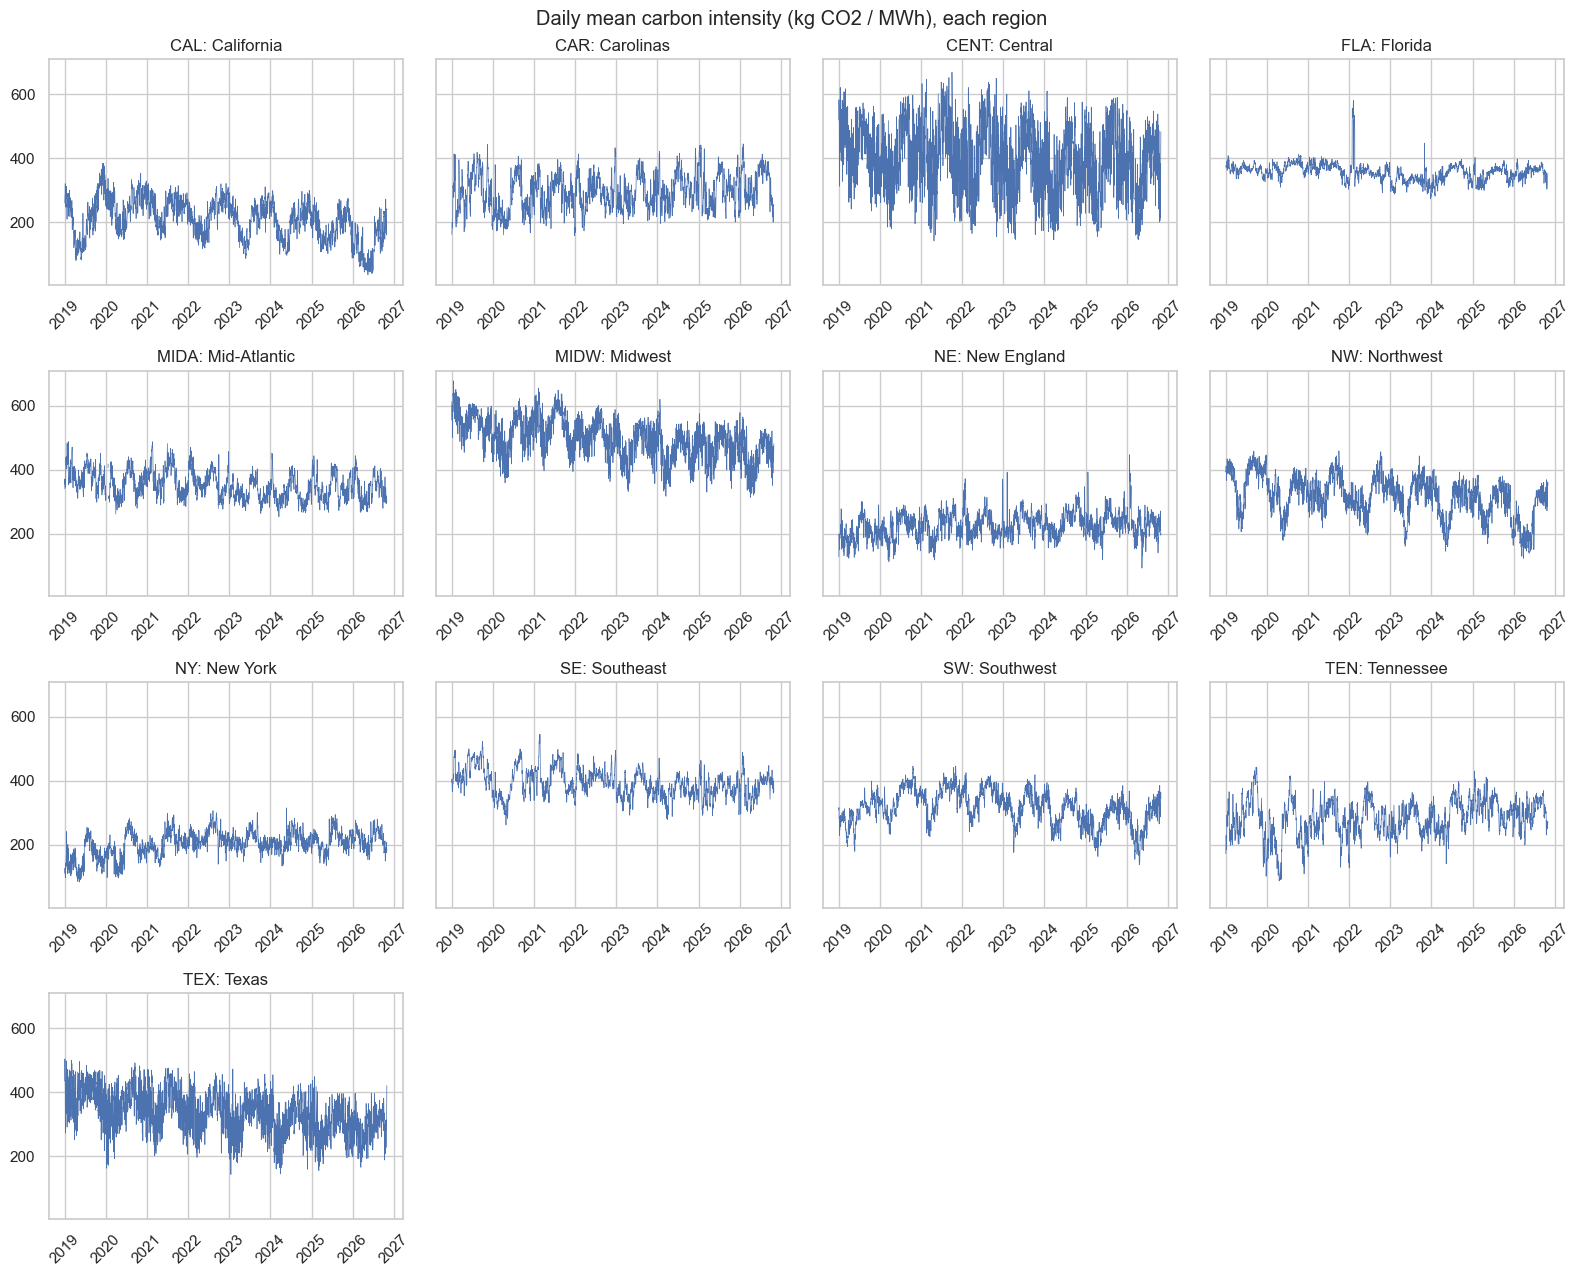

In [31]:
fig, ax = grid13(sharey=True)
for r in REGIONS:
    daily = R[R.region == r].groupby("date").ci.mean()
    ax[r].plot(daily.index, daily.values, lw=0.5, color="C0")
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].tick_params(axis="x", rotation=45)
plt.suptitle("Daily mean carbon intensity (kg CO2 / MWh), each region")
plt.tight_layout()
plt.show()

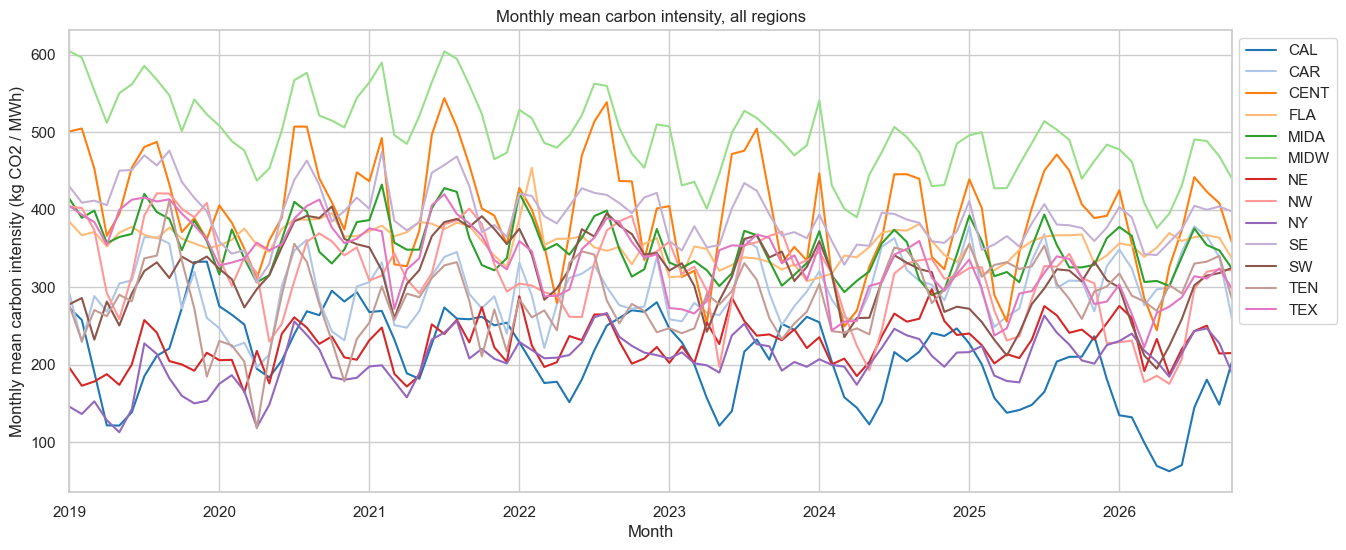

In [32]:
# all together: monthly means
monthly = R.groupby([R.date.dt.to_period("M"), "region"]).ci.mean().unstack()[REGIONS]
monthly.index = monthly.index.to_timestamp()
monthly.plot(figsize=(15, 6), color=[PAL13[r] for r in REGIONS])
plt.xlabel("Month")
plt.ylabel("Monthly mean carbon intensity (kg CO2 / MWh)")
plt.title("Monthly mean carbon intensity, all regions")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

#### (f) Demand vs carbon intensity

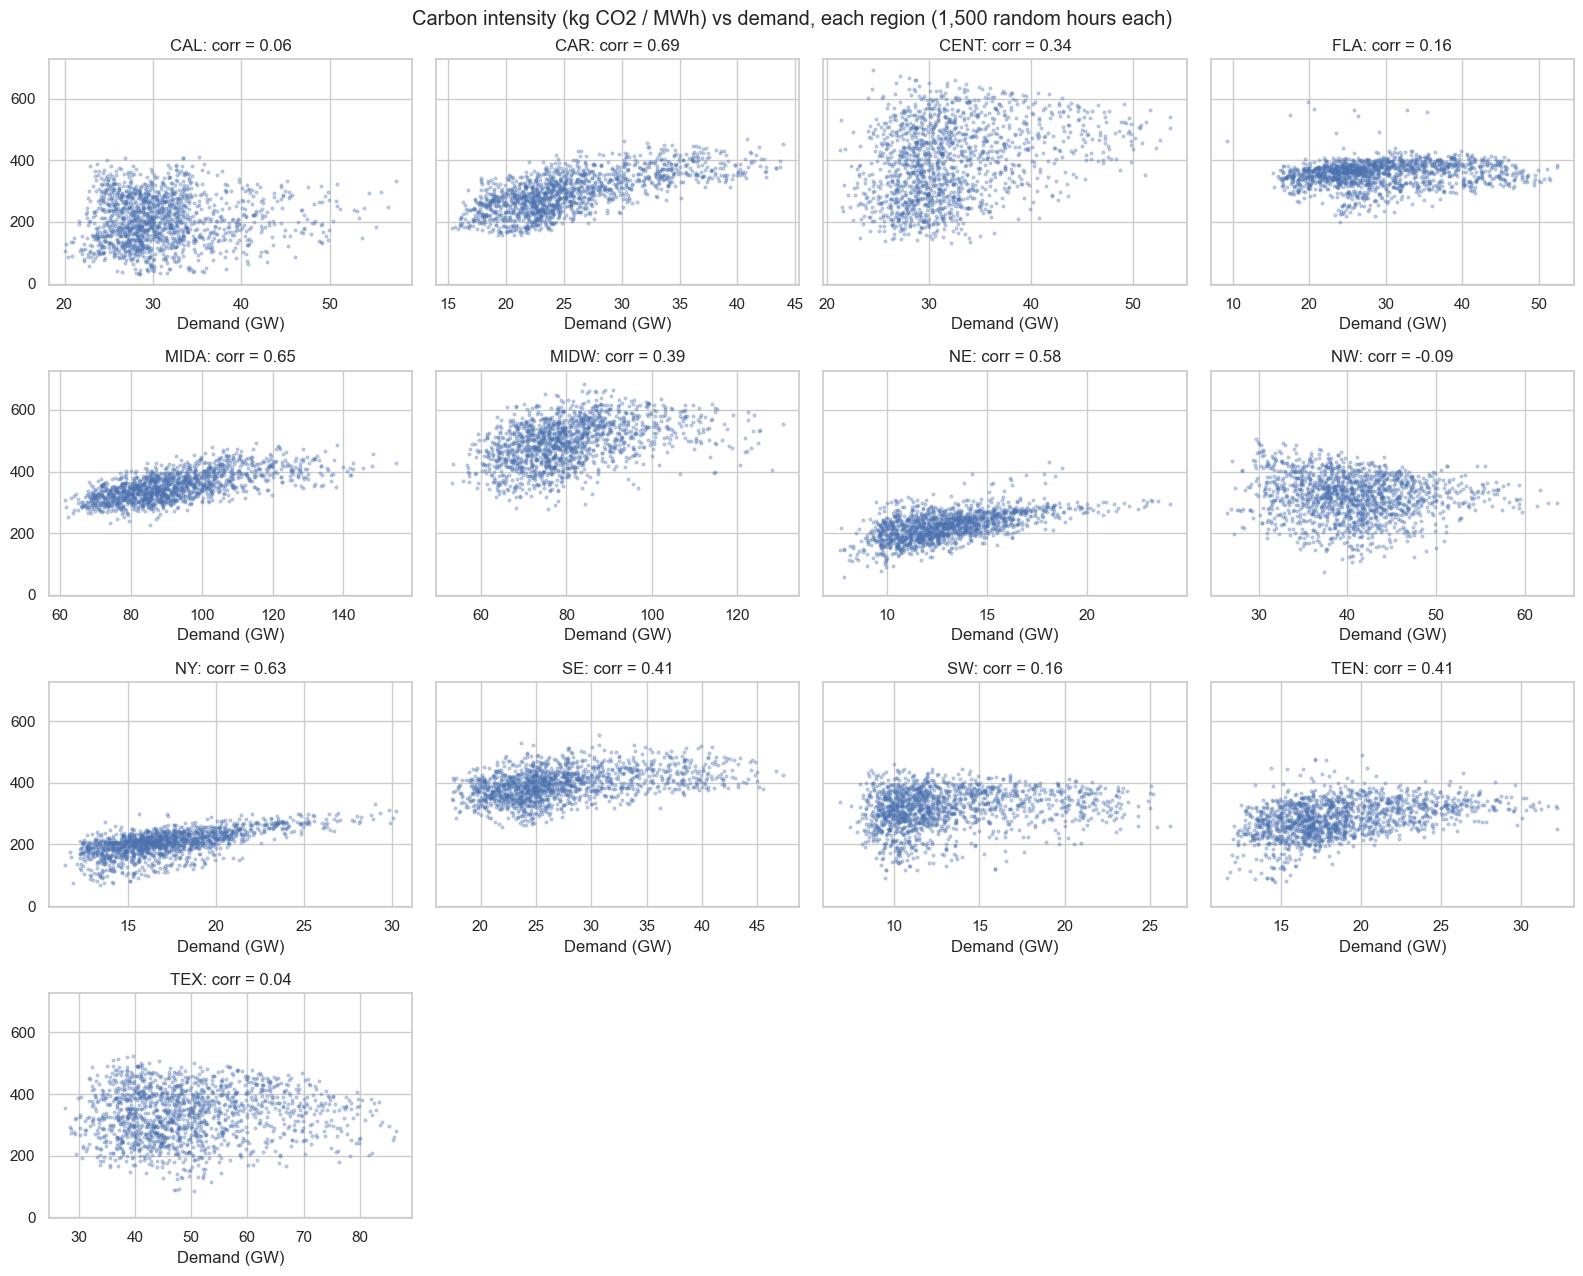

In [33]:
sample = R.dropna(subset=["ci", "demand"]).groupby("region").sample(1500, random_state=0)
fig, ax = grid13(sharex=False, sharey=True)
for r in REGIONS:
    g = sample[sample.region == r]
    ax[r].scatter(g.demand / 1e3, g.ci, s=4, alpha=0.3, color="C0")
    corr = R.loc[R.region == r, "demand"].corr(R.loc[R.region == r, "ci"])
    ax[r].set_title(f"{r}: corr = {corr:.2f}")
    ax[r].set_xlabel("Demand (GW)")
plt.suptitle("Carbon intensity (kg CO2 / MWh) vs demand, each region (1,500 random hours each)")
plt.tight_layout()
plt.show()

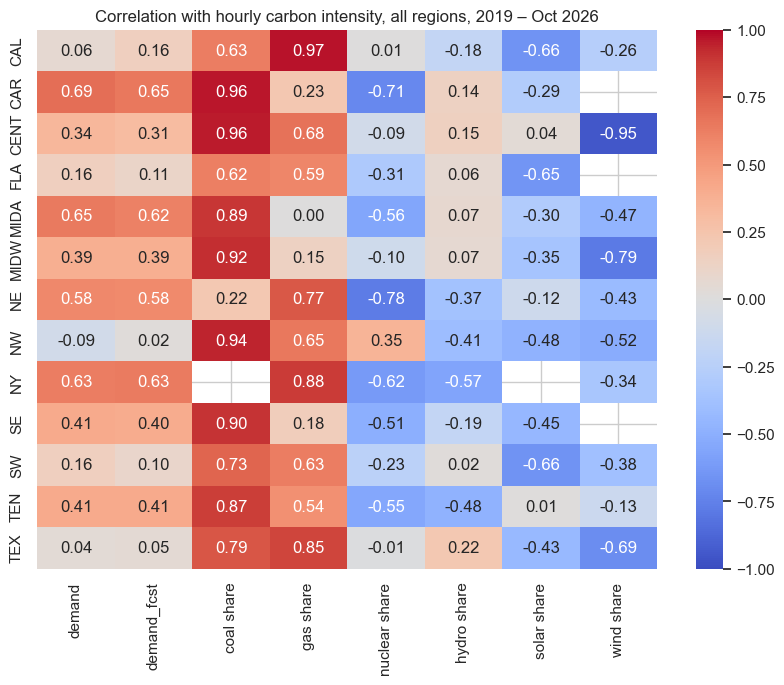

In [34]:
# all together: correlation of carbon intensity with demand and each fuel's share of generation
def drivers(g):
    gen = g[E.FUELS].clip(lower=0)
    share = gen.div(gen.sum(axis=1), axis=0).add_suffix(" share")
    X = pd.concat([g[["demand", "demand_fcst"]], share[["coal share", "gas share", "nuclear share", "hydro share", "solar share", "wind share"]]], axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):   # some fuels are always 0 in some regions
        return X.corrwith(g.ci)

corr_table = pd.DataFrame({r: drivers(R[R.region == r]) for r in REGIONS}).T
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_table, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation with hourly carbon intensity, all regions, 2019 – Oct 2026")
plt.show()

#### (g) Net exports

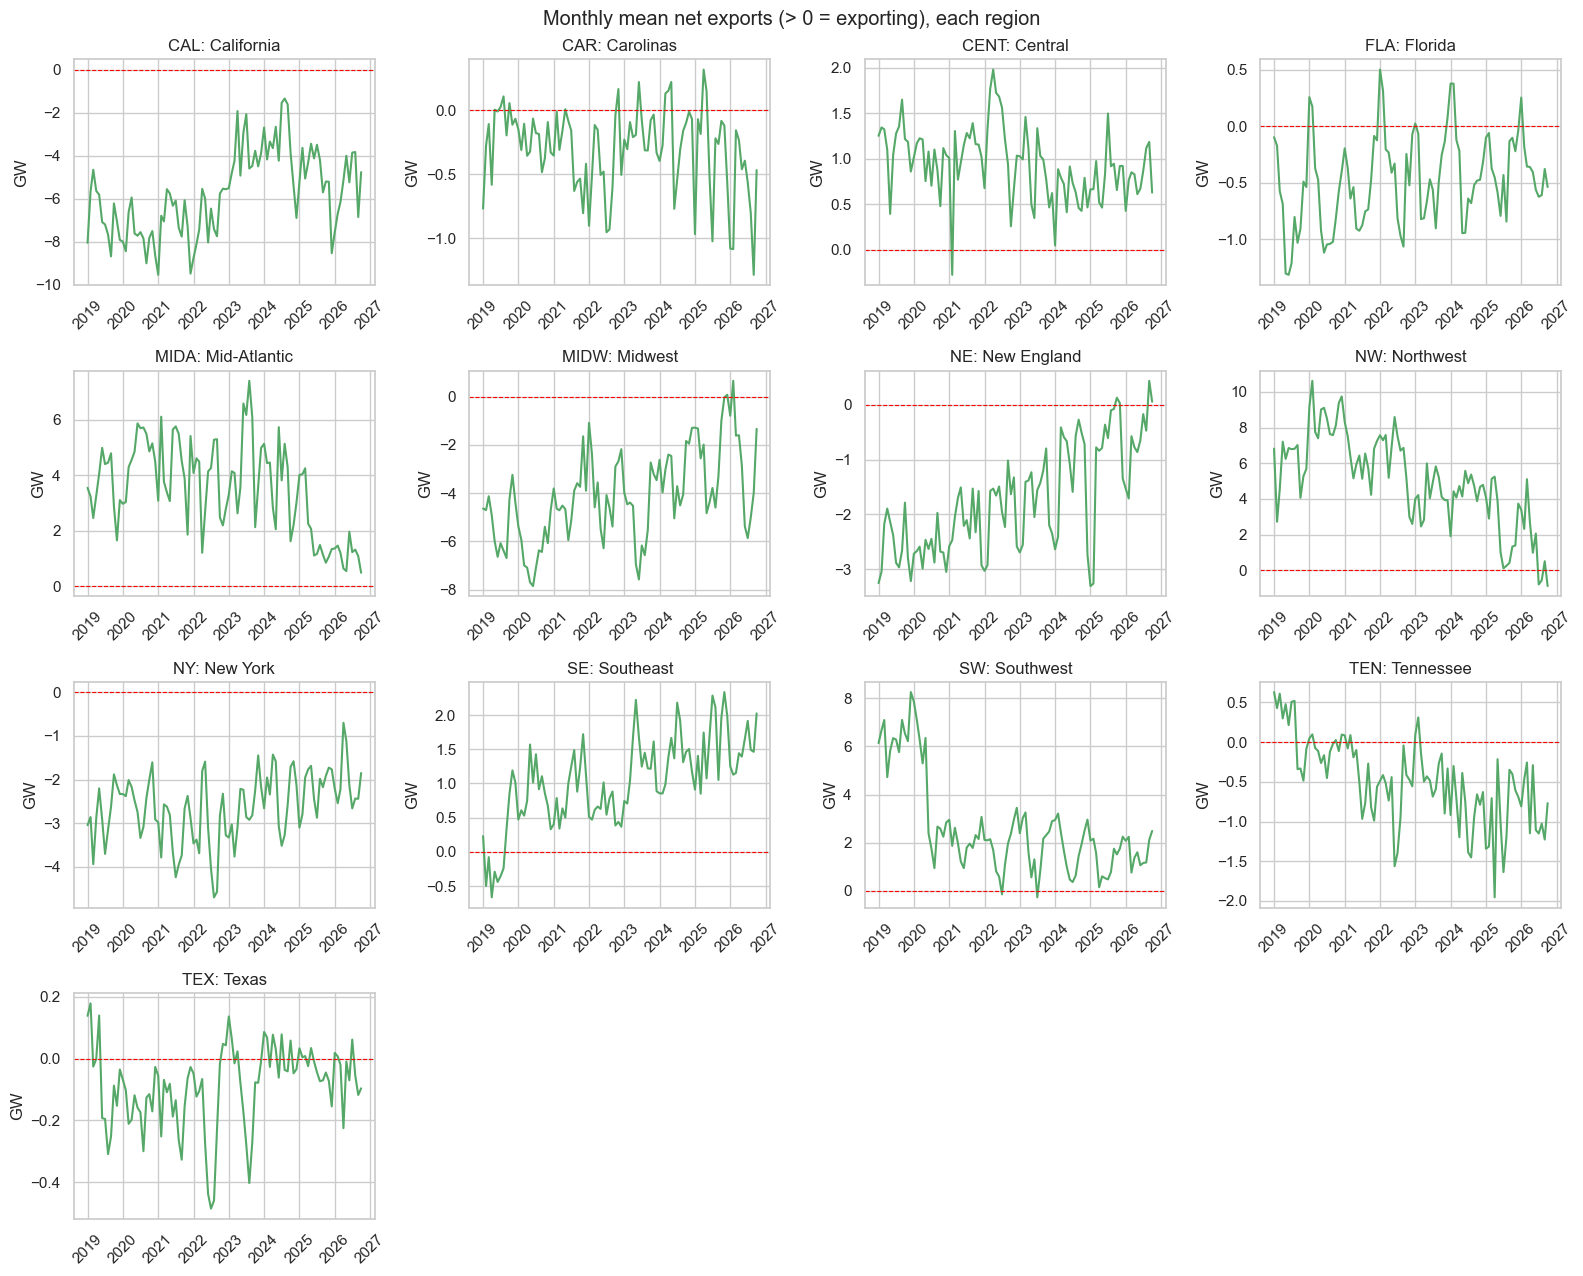

In [35]:
fig, ax = grid13(sharey=False)
for r in REGIONS:
    m = R[R.region == r].groupby(R.date.dt.to_period("M")).interchange.mean() / 1e3
    ax[r].plot(m.index.to_timestamp(), m.values, color="C2")
    ax[r].axhline(0, color="red", linestyle="--", lw=0.8)
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_ylabel("GW")
    ax[r].tick_params(axis="x", rotation=45)
plt.suptitle("Monthly mean net exports (> 0 = exporting), each region")
plt.tight_layout()
plt.show()

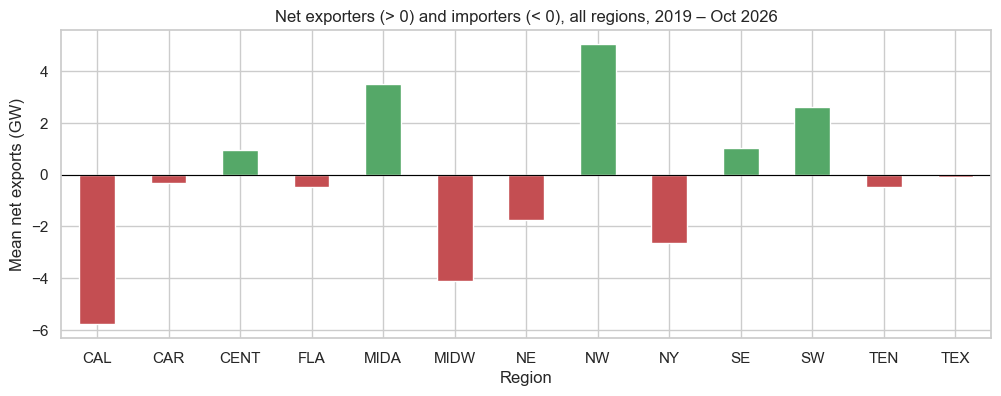

In [36]:
# all together
net = (R.groupby("region").interchange.mean() / 1e3).reindex(REGIONS)
net.plot(kind="bar", figsize=(12, 4), rot=0, color=["C2" if v > 0 else "C3" for v in net])
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("Region")
plt.ylabel("Mean net exports (GW)")
plt.title("Net exporters (> 0) and importers (< 0), all regions, 2019 – Oct 2026")
plt.show()

### 5.1 Polished charts: carbon intensity over time

The charts from here on use the presentation style.

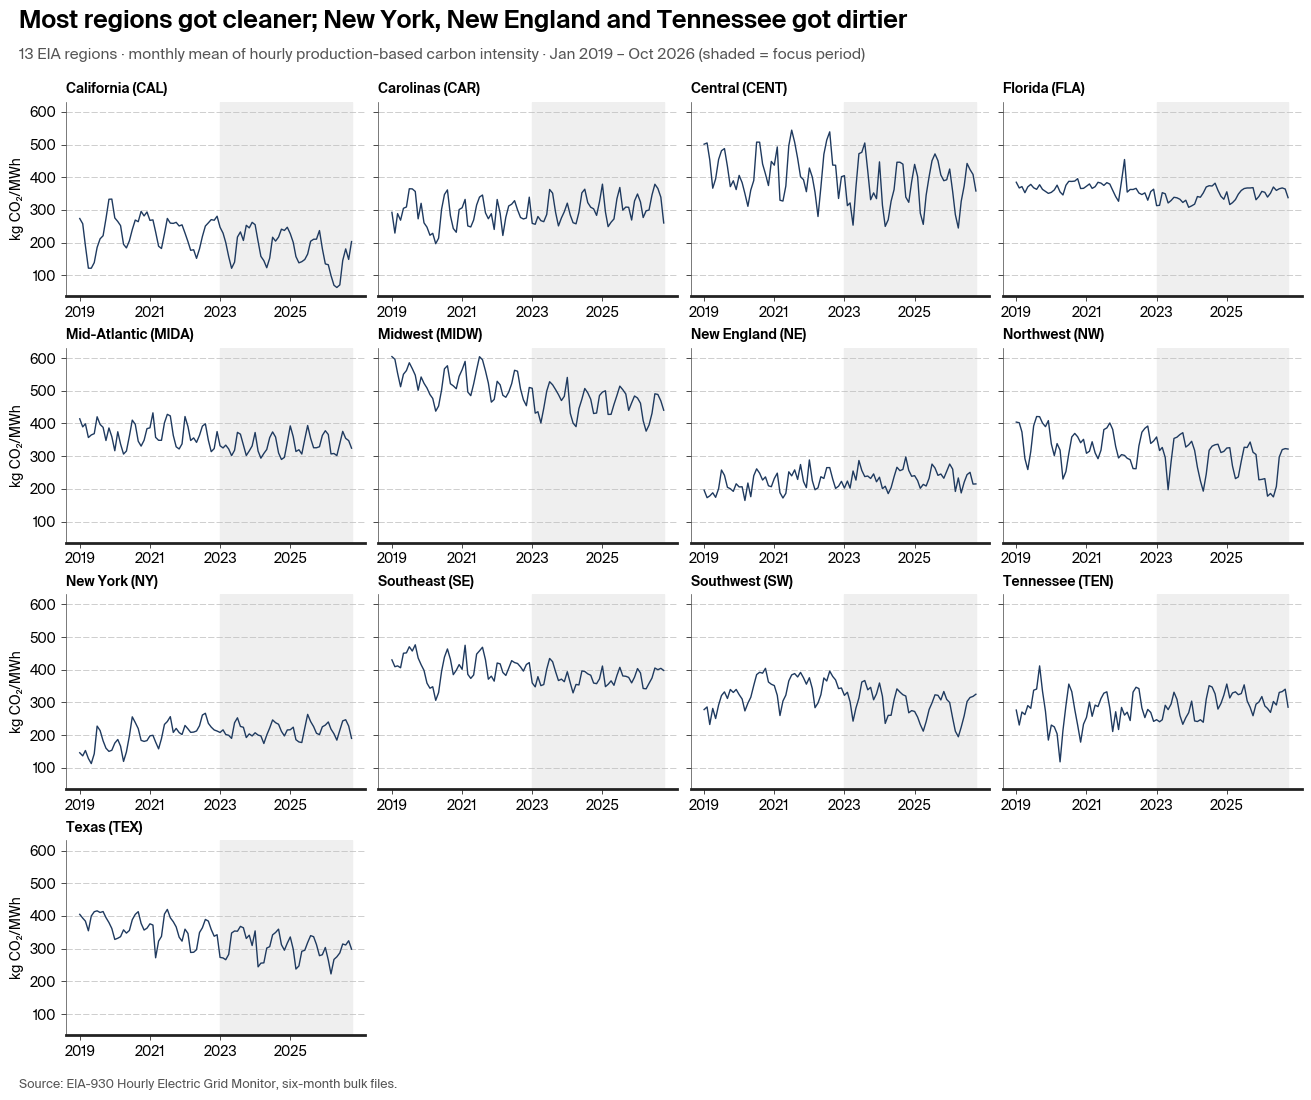

In [37]:
S.set_style()
fig, axes = plt.subplots(4, 4, figsize=(13, 11), sharex=True, sharey=True)
axes = axes.ravel()
for ax, r in zip(axes, REGIONS):
    ax.axvspan(pd.Timestamp(FOCUS_START), monthly.index.max(), color=S.NEUTRAL["shade"], zorder=0)
    ax.plot(monthly.index, monthly[r], color=S.NAVY, lw=S.LINE_PT["medium"])
    ax.set_title(f"{RN[r]} ({r})", fontsize=10)
    S.chart_lines(ax)
    ax.set_xticks(pd.to_datetime(["2019-01-01", "2021-01-01", "2023-01-01", "2025-01-01"]))
    ax.set_xticklabels(["2019", "2021", "2023", "2025"])
    ax.xaxis.set_tick_params(labelbottom=True)
for ax in axes[len(REGIONS):]:
    ax.axis("off")
for ax in axes[::4]:
    ax.set_ylabel("kg CO₂/MWh")
S.frame(fig, "Most regions got cleaner; New York, New England and Tennessee got dirtier",
        "13 EIA regions · monthly mean of hourly production-based carbon intensity · Jan 2019 – Oct 2026 (shaded = focus period)")
S.save(fig, f"{FIG}/01_ci_monthly_by_region.png")

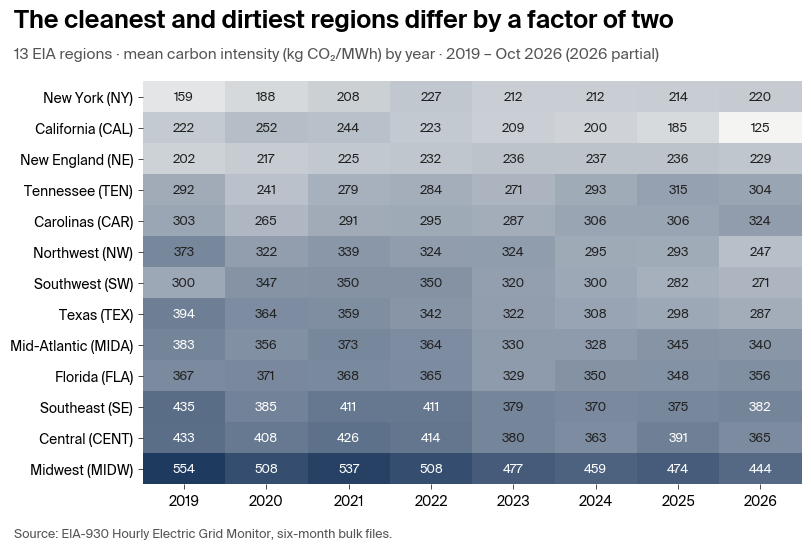

In [38]:
# all together: mean carbon intensity by region and year
order = yearly_ci.mean().sort_values().index
fig, ax = plt.subplots(figsize=S.PANEL["L"])
im = ax.imshow(yearly_ci[order].T.values, aspect="auto", cmap=S.SEQ)
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{RN[r]} ({r})" for r in order])
ax.set_xticks(range(len(yearly_ci))); ax.set_xticklabels(yearly_ci.index)
for i, r in enumerate(order):
    for j, y in enumerate(yearly_ci.index):
        v = yearly_ci.loc[y, r]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 380 else S.NEUTRAL["ink"])
for sp in ax.spines.values(): sp.set_visible(False)
S.frame(fig, "The cleanest and dirtiest regions differ by a factor of two",
        "13 EIA regions · mean carbon intensity (kg CO₂/MWh) by year · 2019 – Oct 2026 (2026 partial)")
S.save(fig, f"{FIG}/02_ci_region_by_year.png")

### 5.2 Polished chart: what each region runs on

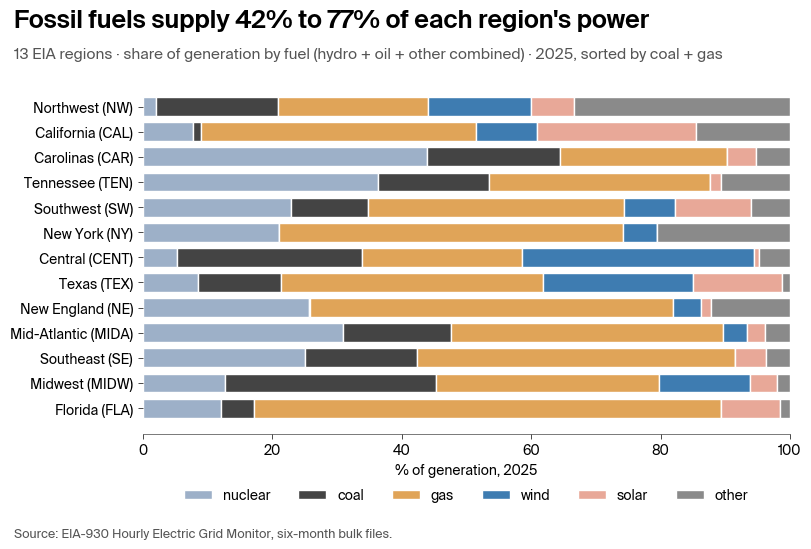

,nuclear,coal,gas,wind,solar,other
region,,,,,,
NW,2.000000,18.900000,23.200001,15.800000,6.8,33.299999
CAL,7.700000,1.300000,42.400002,9.500000,24.6,14.500000
CAR,43.900002,20.600000,25.700001,0.000000,4.5,5.300000
TEN,36.400002,17.100000,34.200001,-0.000000,1.7,10.600000
SW,22.900000,11.900000,39.599998,7.800000,11.8,6.100000
NY,21.100000,0.000000,53.000000,5.300000,0.0,20.500000
CENT,5.300000,28.500000,24.700001,35.900002,0.8,4.700000
TEX,8.500000,12.800000,40.500000,23.299999,13.7,1.200000
NE,25.600000,0.300000,56.099998,4.200000,1.5,12.300000


In [39]:
m25 = R[R.year == 2025].copy()
m25["other"] = m25[["hydro", "oil", "other"]].sum(axis=1)       # small fuels combined, as in style.FUEL_COLOR
share = m25.groupby("region")[list(S.FUEL_COLOR)].sum()
share = share.div(share.sum(axis=1), axis=0) * 100
share = share.loc[share.eval("coal + gas").sort_values().index]   # cleanest mix at the top

fig, ax = plt.subplots(figsize=S.PANEL["L"])
left = np.zeros(len(share))
for f, col in S.FUEL_COLOR.items():
    ax.barh(range(len(share)), share[f], left=left, color=col, edgecolor="white", linewidth=1, height=0.75, label=f)
    left += share[f].values
ax.set_yticks(range(len(share))); ax.set_yticklabels([f"{RN[r]} ({r})" for r in share.index])
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% of generation, 2025")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.12))
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
S.frame(fig, "Fossil fuels supply 42% to 77% of each region's power",
        "13 EIA regions · share of generation by fuel (hydro + oil + other combined) · 2025, sorted by coal + gas")
S.save(fig, f"{FIG}/03_generation_mix_by_region.png")
share.round(1)

### 5.3 Why we focus on 2023 onward

The full timeline is useful context, but the early years are a poor guide to today's grid:

- **Data problems cluster before 2023:** PJM's broken fuel mix in January 2020, interchange that doesn't add up in several regions in 2019–2020, and most of the BA reshuffling.
- **2020–2021 are COVID years**, with unusual demand.
- **The grid changed quickly.** Solar's share of generation grew from 1% to 14% in Texas, from 3% to 12% in the Southwest, and from 1.5% to 9% in Florida between 2019 and 2025. Even within 2023–2026 the daily shape keeps moving (Section 6).

So, as a team, the rest of the analysis uses **Jan 2023 – Oct 2026** (33,599 hours per region).

## 6. EDA: focus period (Jan 2023 – Oct 2026)

In [40]:
F = R[R.date >= FOCUS_START].copy()
print(f"focus period: {F.date.min().date()} → {F.date.max().date()},  {len(F):,} rows ({len(F) // 13:,} hours per region)")
F.groupby("region_name").ci.describe().round(0).sort_values("mean")

focus period: 2023-01-01 → 2026-10-31,  436,788 rows (33,599 hours per region)


,count,mean,std,min,25%,50%,75%,max
region_name,,,,,,,,
California,33597.0,182.0,72.0,22.0,129.0,178.0,238.0,433.0
New York,33586.0,214.0,31.0,107.0,193.0,214.0,235.0,350.0
New England,33597.0,235.0,42.0,54.0,208.0,235.0,261.0,465.0
Northwest,33589.0,292.0,72.0,76.0,243.0,300.0,344.0,489.0
Southwest,33578.0,294.0,64.0,87.0,256.0,302.0,342.0,456.0
Tennessee,33597.0,296.0,48.0,126.0,260.0,297.0,331.0,452.0
Carolinas,33599.0,305.0,60.0,144.0,259.0,302.0,351.0,471.0
Texas,33578.0,305.0,79.0,73.0,246.0,307.0,365.0,502.0
Mid-Atlantic,33589.0,336.0,40.0,210.0,306.0,332.0,362.0,458.0


### 6.0 Basic EDA on the focus period

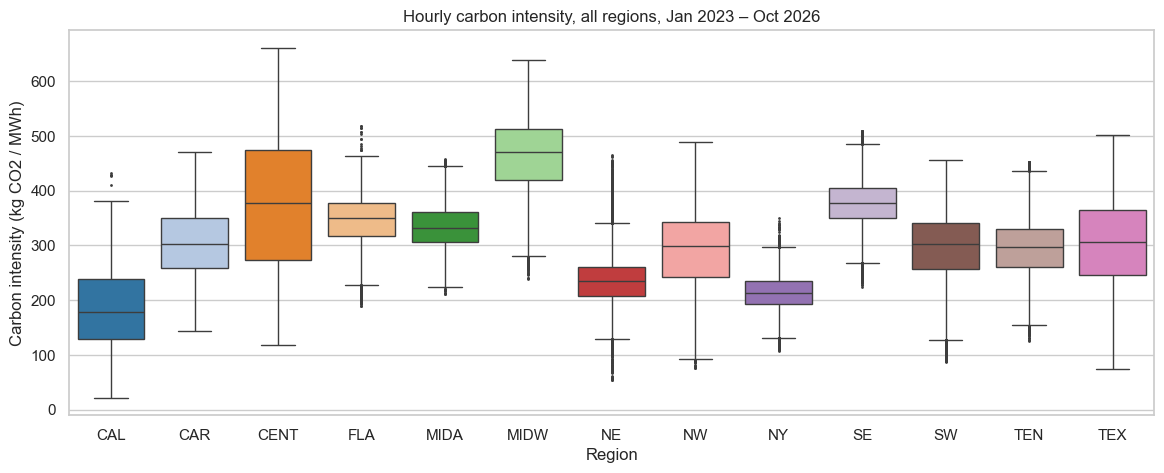

In [41]:
plt.rcdefaults()
sns.set_theme(style="whitegrid")

# all together: distribution of the target
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=F, x="region", y="ci", order=REGIONS, palette=PAL13, hue="region", legend=False, fliersize=1, ax=ax)
ax.set_xlabel("Region")
ax.set_ylabel("Carbon intensity (kg CO2 / MWh)")
ax.set_title("Hourly carbon intensity, all regions, Jan 2023 – Oct 2026")
plt.show()

#### (a) The daily shape: mean carbon intensity by hour, one line per year

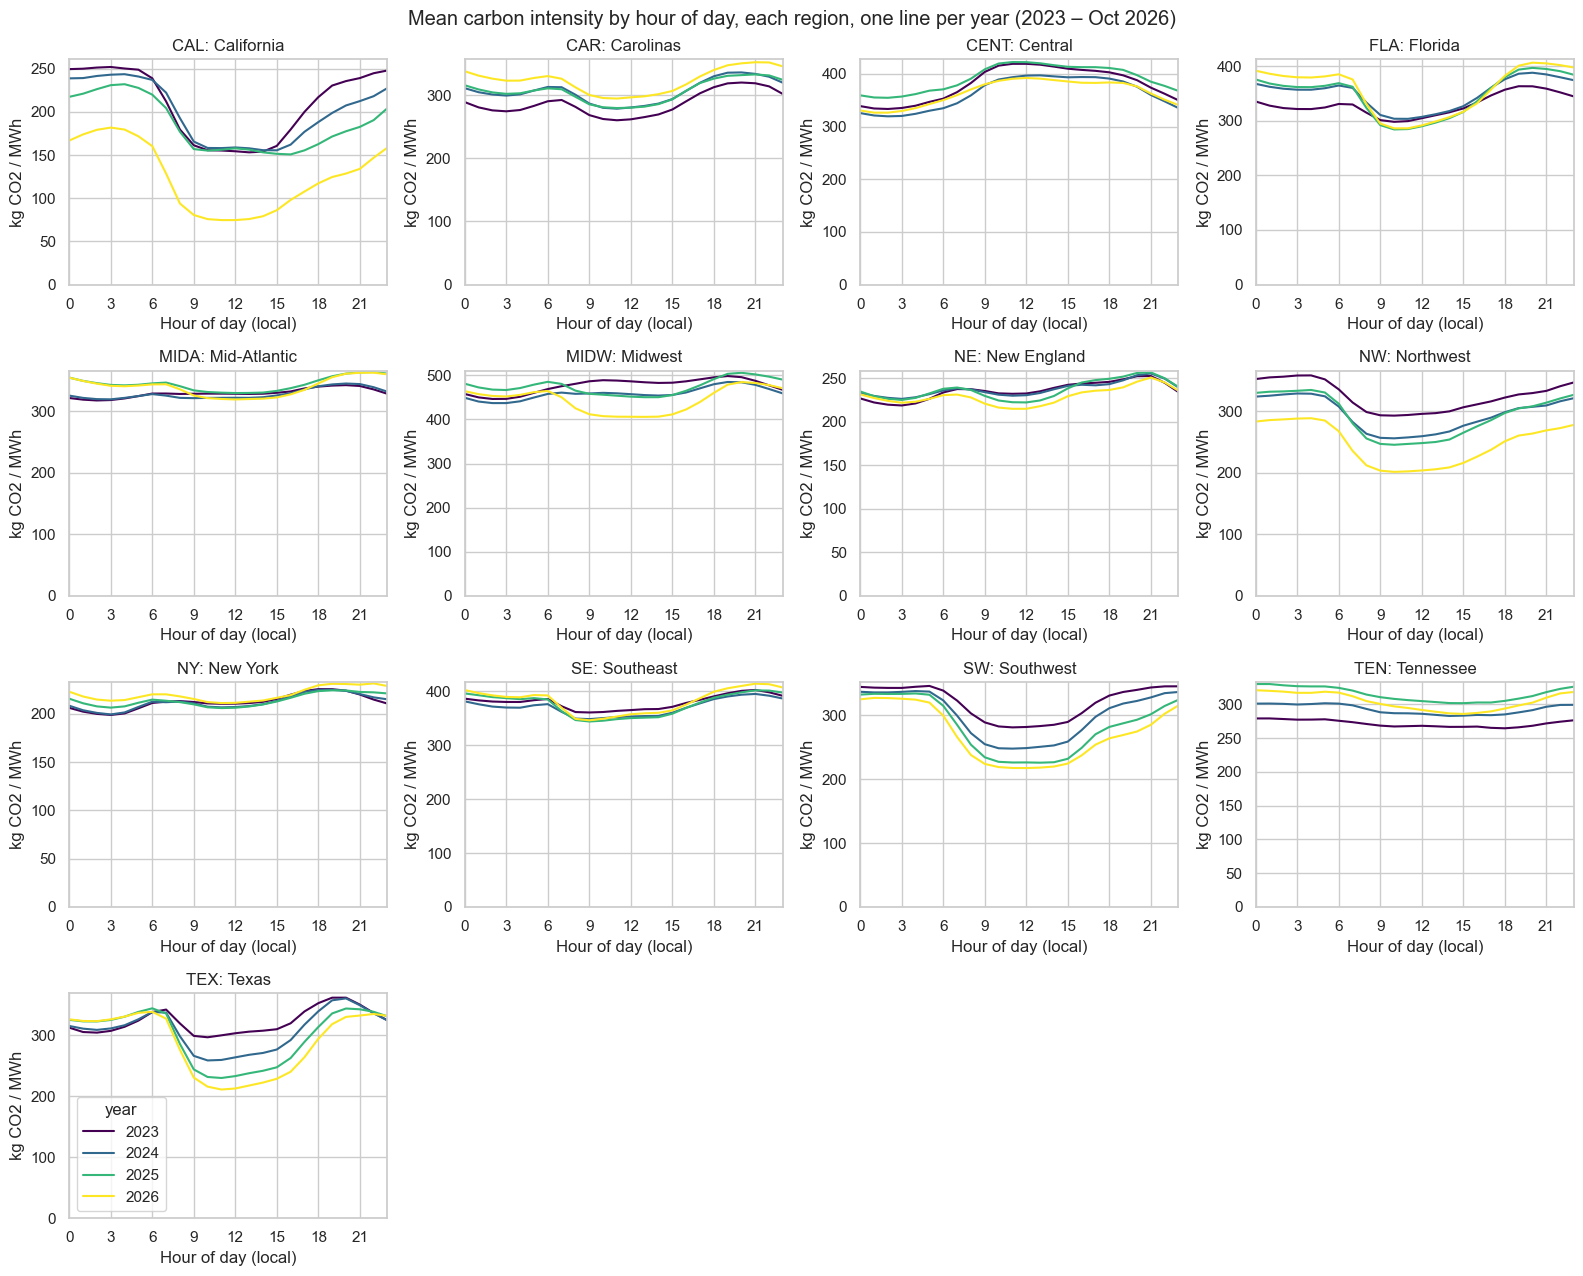

In [42]:
fig, ax = grid13(sharey=False)
for r in REGIONS:
    sns.lineplot(data=F[F.region == r], x="hour", y="ci", hue="year", palette="viridis", errorbar=None, ax=ax[r], legend=(r == "TEX"))
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("Hour of day (local)")
    ax[r].set_ylabel("kg CO2 / MWh")
    ax[r].set_xticks(range(0, 24, 3))
    ax[r].set_xlim(0, 23)
    ax[r].set_ylim(bottom=0)
plt.suptitle("Mean carbon intensity by hour of day, each region, one line per year (2023 – Oct 2026)")
plt.tight_layout()
plt.show()

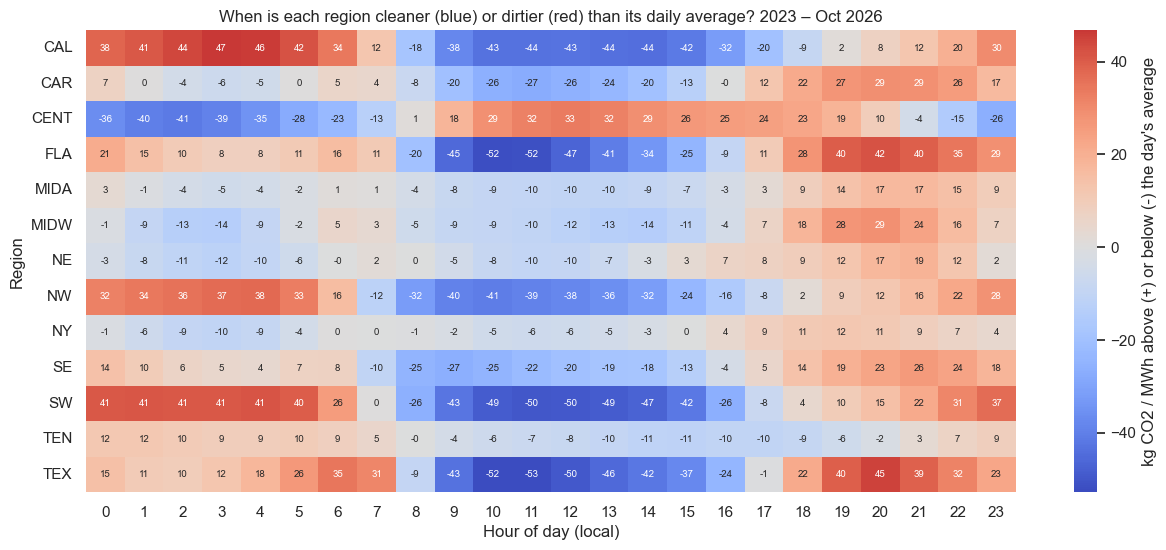

In [43]:
# all together: each hour's carbon intensity minus its own day's average (removes the level, keeps the daily shape)
F["ci_dev"] = F.ci - F.groupby(["region", "date"]).ci.transform("mean")
dev = F.groupby(["region", "hour"]).ci_dev.mean().unstack().reindex(REGIONS)
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(dev, cmap="coolwarm", center=0, annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "kg CO2 / MWh above (+) or below (-) the day's average"}, ax=ax)
ax.set_xlabel("Hour of day (local)")
ax.set_ylabel("Region")
ax.set_title("When is each region cleaner (blue) or dirtier (red) than its daily average? 2023 – Oct 2026")
plt.show()

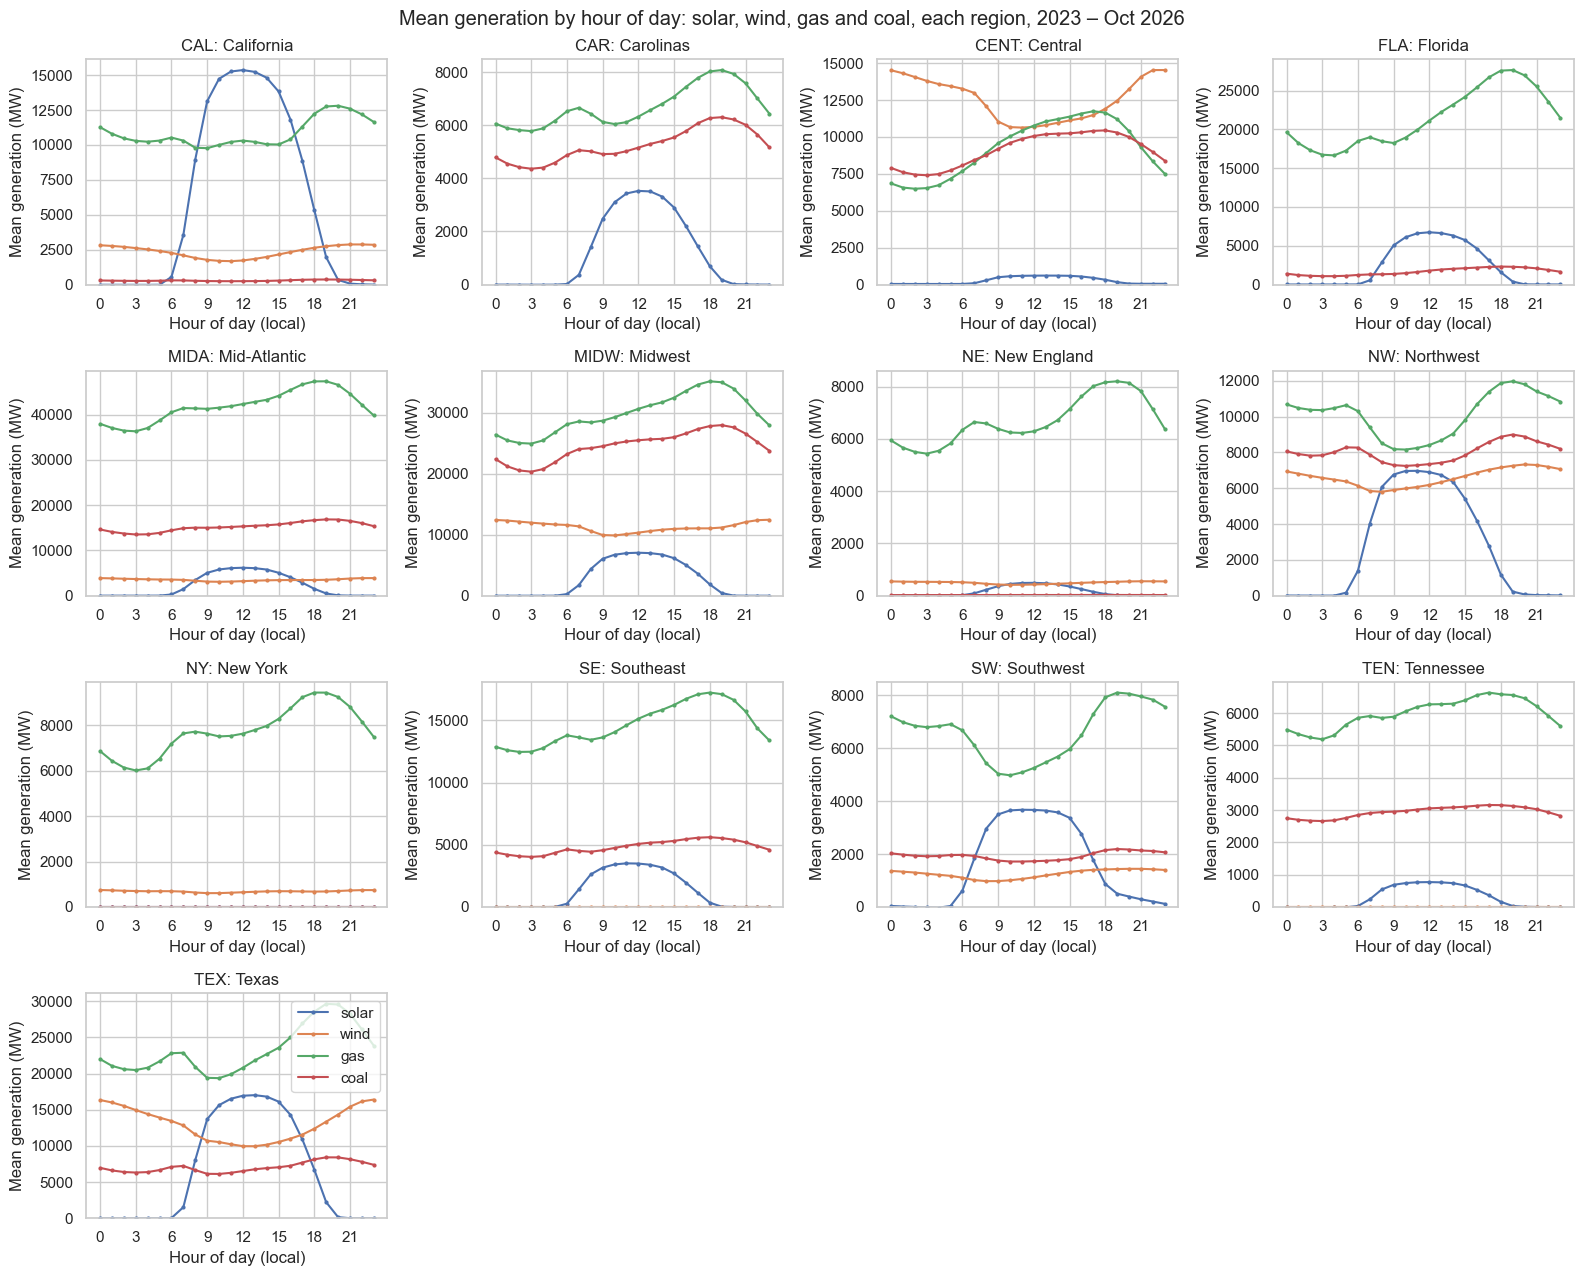

In [44]:
# solar, wind, gas and coal by hour of day: the reason the clean hours move
# y-axis starts at 0 so the size of each fuel is shown honestly; each region has its own scale
fig, ax = grid13(sharex=False, sharey=False)
for r in REGIONS:
    F[F.region == r].groupby("hour")[["solar", "wind", "gas", "coal"]].mean().plot(ax=ax[r], marker="o", ms=2, legend=(r == "TEX"))
    ax[r].set_ylim(bottom=0)
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("Hour of day (local)")
    ax[r].set_ylabel("Mean generation (MW)")
    ax[r].set_xticks(range(0, 24, 3))
plt.suptitle("Mean generation by hour of day: solar, wind, gas and coal, each region, 2023 – Oct 2026")
plt.tight_layout()
plt.show()

#### (b) The cleanest hour of each day

For every complete day we find the one hour with the **lowest carbon intensity**, then count how often each hour wins. A bar at 12 that reaches 30% means: on 30% of days, the 12:00–13:00 hour was the cleanest hour of that day. Each panel's bars add up to 100%.

**Read the bar at 23 with care.** In Central, the Midwest, New England and New York, hour 23 wins more often than its neighbours. That is a calendar edge effect, not a cleaner hour. On those nights carbon intensity is still falling as wind picks up, so the true low comes after midnight, on the next calendar day. On about 90% of the days where 23:00 wins, the hour after midnight is even lower. The real pattern in those regions is "cleanest overnight", spread across 23:00–05:00.

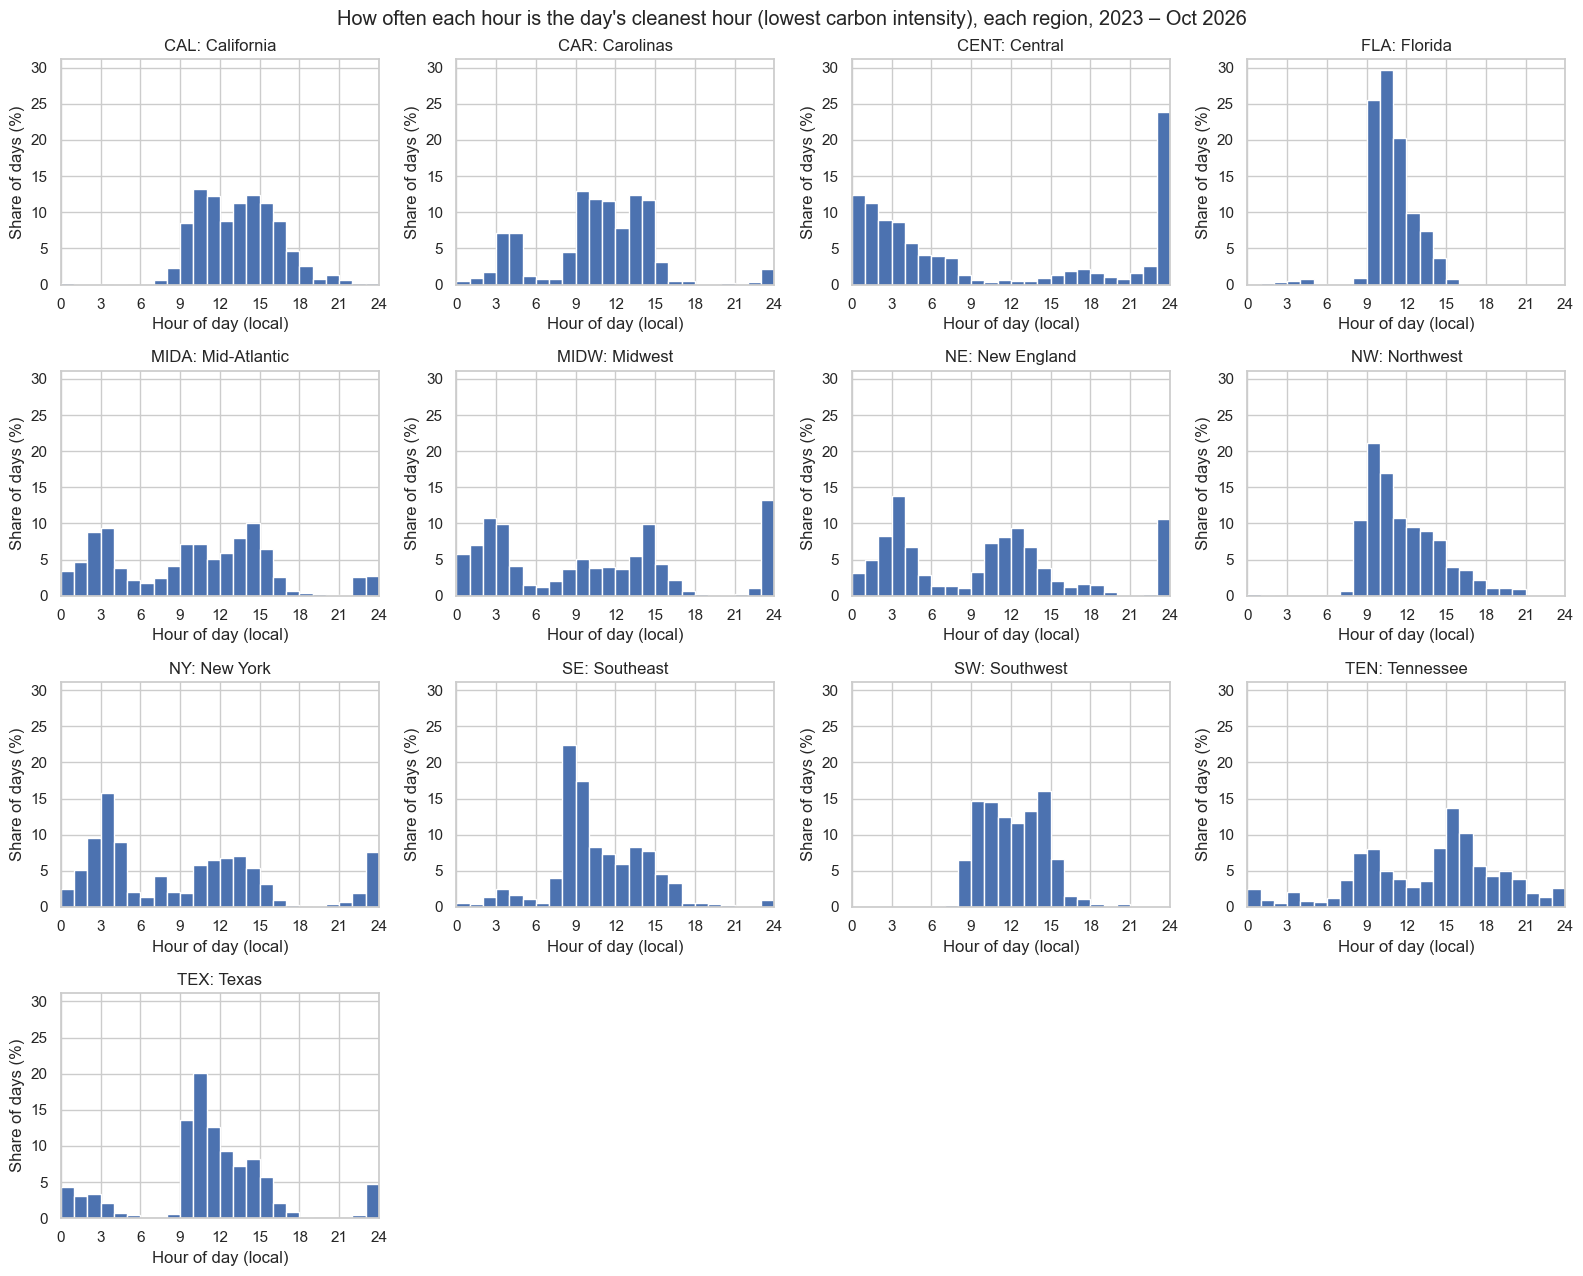

In [45]:
full = F.dropna(subset=["ci"])
full = full[full.groupby(["region", "date"]).ci.transform("size") == 24]       # complete days only
best = full.loc[full.groupby(["region", "date"]).ci.idxmin()]

fig, ax = grid13(sharex=False, sharey=True)
for r in REGIONS:
    share = best[best.region == r].hour.value_counts(normalize=True).mul(100).reindex(range(24), fill_value=0)
    ax[r].bar(share.index, share.values, width=1, align="edge", color="C0", edgecolor="white")  # bar h spans h:00-h+1:00
    ax[r].set_xlim(0, 24)
    ax[r].set_xticks(range(0, 25, 3))
    ax[r].set_title(f"{r}: {RN[r]}")
    ax[r].set_xlabel("Hour of day (local)")
    ax[r].set_ylabel("Share of days (%)")
    ax[r].yaxis.set_tick_params(labelleft=True)   # same scale on every panel, numbers on every panel
plt.suptitle("How often each hour is the day's cleanest hour (lowest carbon intensity), each region, 2023 – Oct 2026")
plt.tight_layout()
plt.show()

In [46]:
# all together: share of days whose cleanest hour is overnight (0-5) vs midday (10-15), by year
when = best.assign(overnight=best.hour.between(0, 5), midday=best.hour.between(10, 15))
when.groupby(["region_name", "year"])[["overnight", "midday"]].mean().mul(100).round(0).unstack()

overnight                   midday                  
year              2023  2024  2025  2026   2023  2024  2025  2026
region_name                                                      
California         0.0   1.0   1.0   0.0   84.0  70.0  39.0  88.0
Carolinas         25.0  19.0  20.0   9.0   56.0  57.0  58.0  64.0
Central           53.0  51.0  47.0  54.0    2.0   4.0   6.0   4.0
Florida            6.0   1.0   0.0   0.0   60.0  75.0  76.0  77.0
Mid-Atlantic      57.0  42.0  19.0   7.0   17.0  30.0  57.0  71.0
Midwest           63.0  52.0  27.0  10.0    6.0  18.0  45.0  61.0
New England       57.0  41.0  31.0  28.0   24.0  35.0  45.0  48.0
New York          56.0  50.0  35.0  32.0   18.0  29.0  44.0  50.0
Northwest          1.0   0.0   0.0   0.0   52.0  55.0  61.0  64.0
Southeast         10.0  13.0   3.0   4.0   45.0  35.0  48.0  41.0
Southwest          0.0   0.0   0.0   0.0   74.0  70.0  77.0  79.0
Tennessee         12.0   8.0   4.0   7.0   27.0  35.0  42.0  45.0
Texas             35.0  13.0   6.0   1.0   28.0  59.0  81.0  90.0

#### (c) How much does picking the hour matter?

For each complete day: how much cleaner is the **best hour** (and the best **4-hour block**) than the **day's average hour**? This is the most a perfect scheduler could save for a flexible job, i.e. the size of the prize.

In [47]:
W = full.pivot_table(index=["region", "date"], columns="hour", values="ci")
day_mean = W.mean(axis=1)
prize = pd.DataFrame({
    "within-day spread, max − min (kg/MWh)": W.max(axis=1) - W.min(axis=1),
    "best hour vs day average (% cleaner)": (1 - W.min(axis=1) / day_mean) * 100,
    "best 4-h block vs day average (% cleaner)": (1 - W.T.rolling(4).mean().T.min(axis=1) / day_mean) * 100,
}).reset_index()
prize["year"] = prize.date.dt.year
prize_region = prize.groupby("region").median(numeric_only=True).drop(columns="year").reindex(REGIONS)
prize_region.round(1)

,"within-day spread, max − min (kg/MWh)",best hour vs day average (% cleaner),best 4-h block vs day average (% cleaner)
region,,,
CAL,111.900002,29.799999,27.1
CAR,83.900002,14.000000,12.1
CENT,166.300003,22.799999,19.2
FLA,99.800003,16.000000,14.4
MIDA,45.400002,6.200000,5.3
MIDW,92.099998,9.900000,8.3
NE,49.799999,11.200000,9.0
NW,102.000000,16.700001,15.1
NY,38.200001,9.300000,7.5


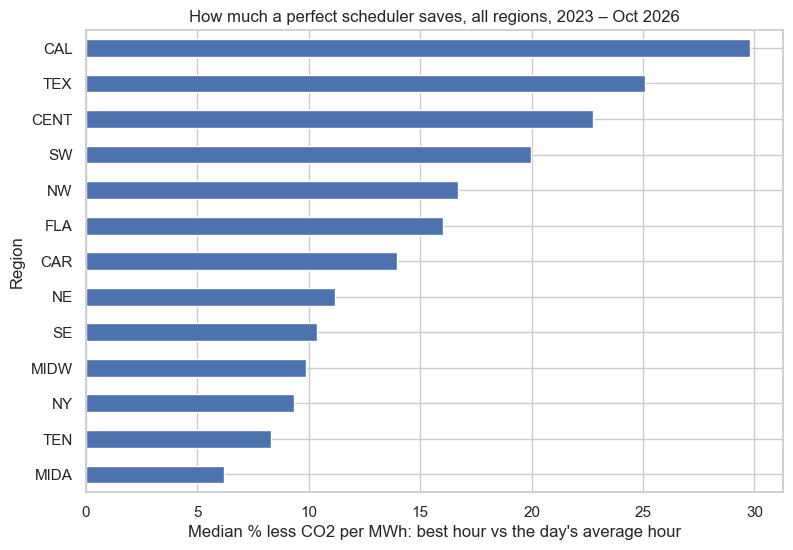

median best-hour saving (%) by region and year:


year,2023,2024,2025,2026
region,,,,
CAL,30.600000,27.700001,25.200001,44.900002
CAR,15.000000,13.500000,13.700000,13.400000
CENT,24.799999,22.200001,22.400000,22.000000
FLA,11.100000,14.400000,19.500000,20.700001
MIDA,5.400000,5.800000,6.800000,8.300000
MIDW,9.600000,9.200000,8.800000,12.300000
NE,10.900000,9.700000,12.500000,12.700000
NW,12.900000,16.100000,18.600000,21.700001
NY,9.400000,9.900000,8.500000,9.100000


In [48]:
# all together
prize_region["best hour vs day average (% cleaner)"].sort_values().plot(kind="barh", figsize=(9, 6), color="C0")
plt.xlabel("Median % less CO2 per MWh: best hour vs the day's average hour")
plt.ylabel("Region")
plt.title("How much a perfect scheduler saves, all regions, 2023 – Oct 2026")
plt.show()

print("median best-hour saving (%) by region and year:")
prize.groupby(["region", "year"])["best hour vs day average (% cleaner)"].median().unstack().reindex(REGIONS).round(1)

#### (d) Energy mix and flows between regions

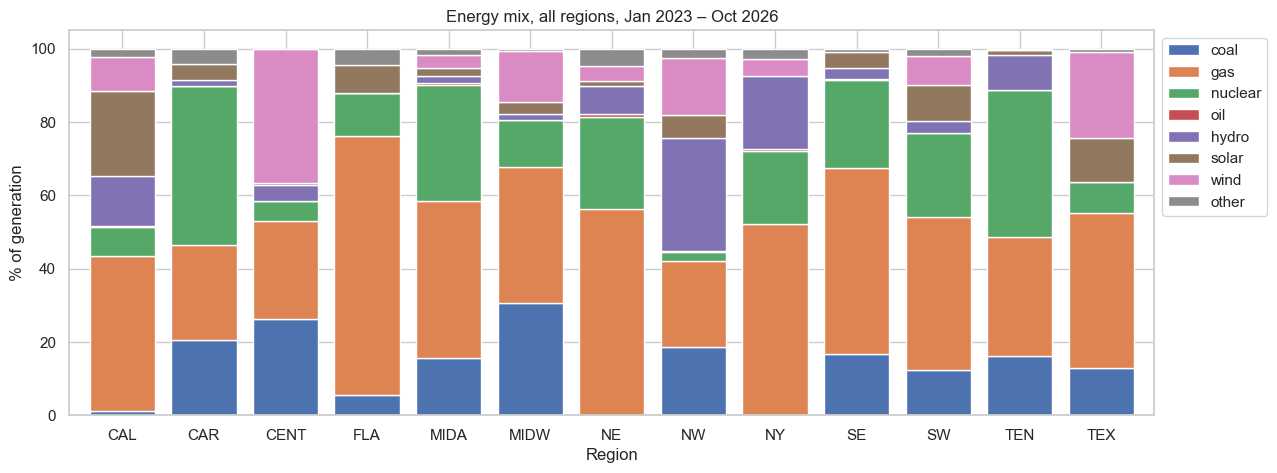

In [49]:
mix_f = F.groupby("region")[E.FUELS].sum().reindex(REGIONS)
mix_f = mix_f.div(mix_f.sum(axis=1), axis=0) * 100
mix_f.plot(kind="bar", stacked=True, figsize=(14, 5), rot=0, width=0.8)
plt.xlabel("Region")
plt.ylabel("% of generation")
plt.title("Energy mix, all regions, Jan 2023 – Oct 2026")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

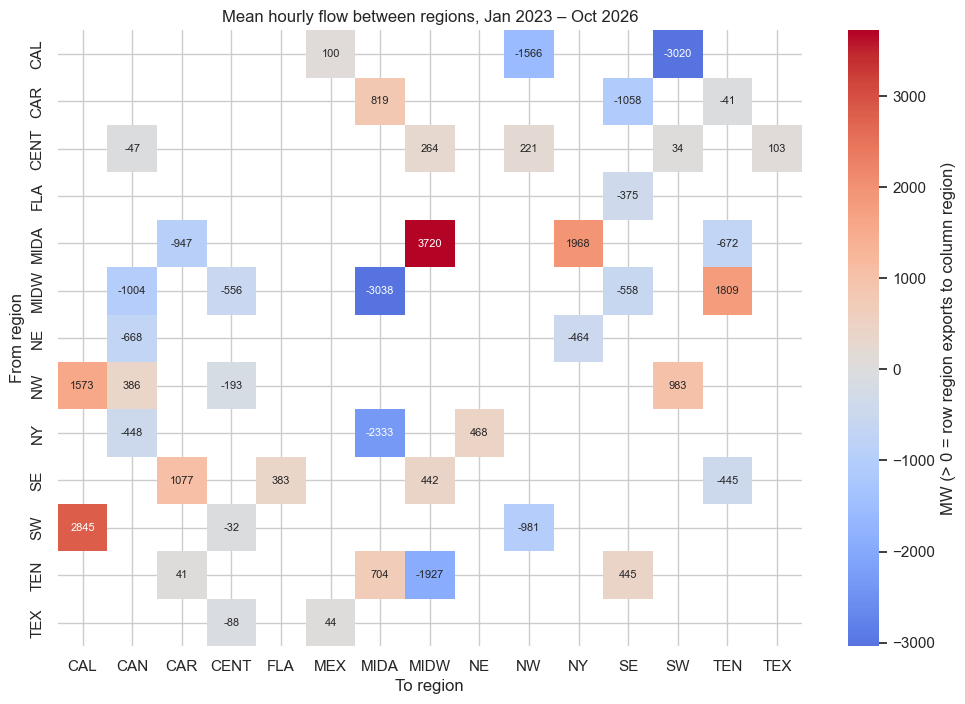

In [50]:
# mean flow between regions (row exports to column if > 0), focus period
ff = flows[flows.utc_end >= FOCUS_START]
matrix = ff.groupby(["region", "to_region"]).mw.mean().unstack()
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(matrix, cmap="coolwarm", center=0, annot=True, fmt=".0f", annot_kws={"size": 8},
            cbar_kws={"label": "MW (> 0 = row region exports to column region)"}, ax=ax)
ax.set_xlabel("To region")
ax.set_ylabel("From region")
ax.set_title("Mean hourly flow between regions, Jan 2023 – Oct 2026")
plt.show()

### 6.1 Polished charts

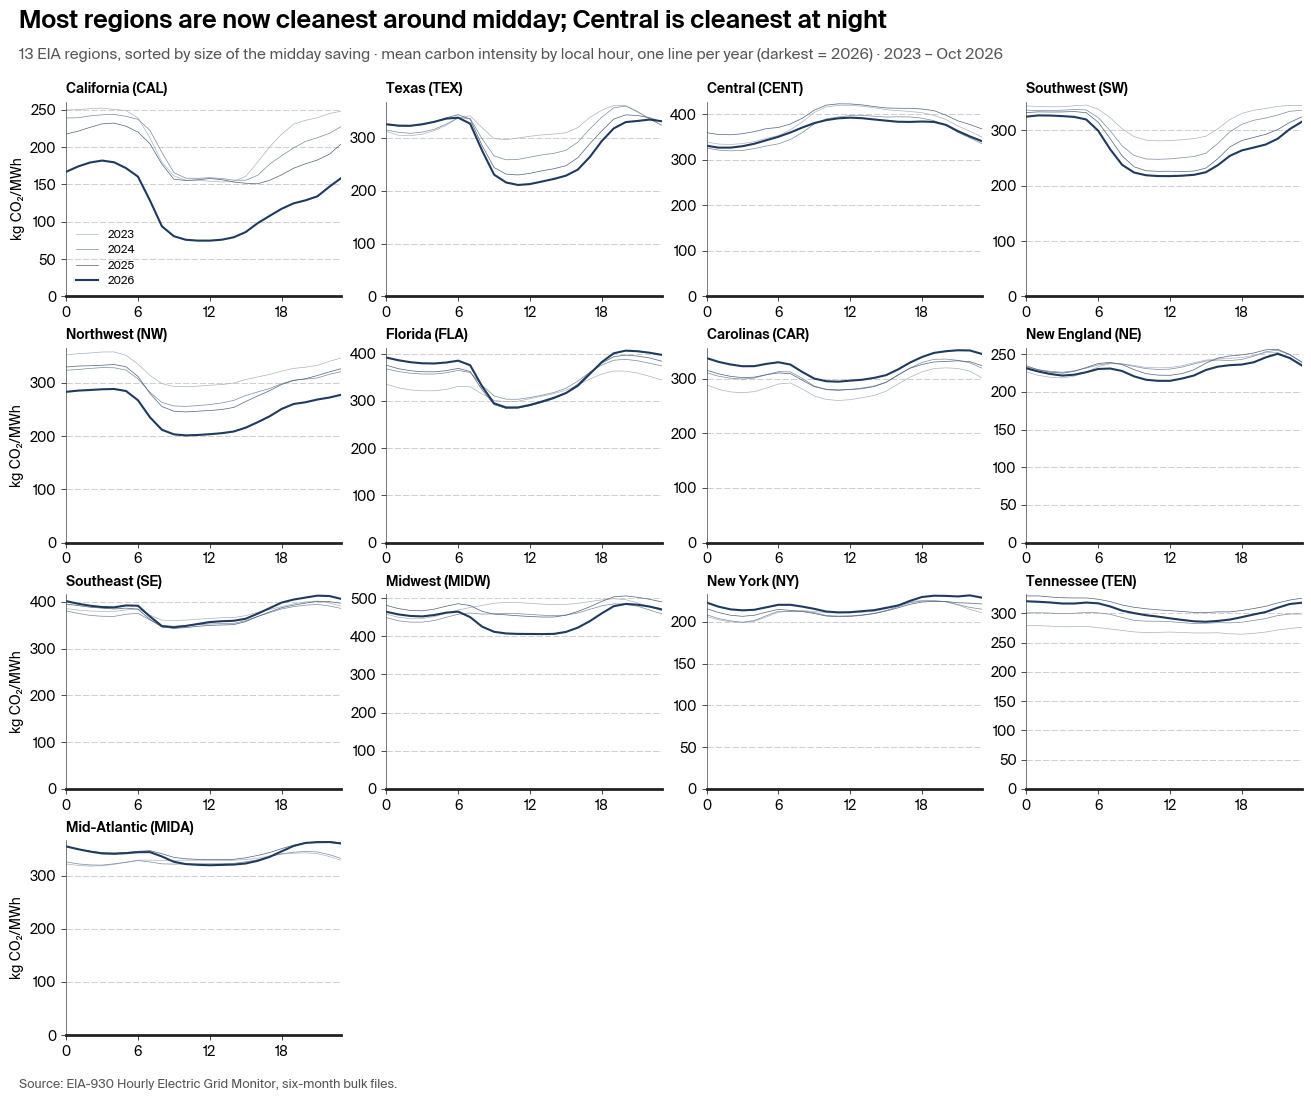

In [51]:
S.set_style()
order = prize_region["best hour vs day average (% cleaner)"].sort_values(ascending=False).index
fig, axes = plt.subplots(4, 4, figsize=(13, 11), sharex=True)
axes = axes.ravel()
years = sorted(F.year.unique())
for ax, r in zip(axes, order):
    g = F[F.region == r]
    for i, y in enumerate(years):
        p = g[g.year == y].groupby("hour").ci.mean()
        ax.plot(p.index, p.values, color=S.SEQ(0.35 + 0.65 * i / (len(years) - 1)),
                lw=S.LINE_PT["heavy"] if y == years[-1] else S.LINE_PT["light"], label=str(y))
    ax.set_title(f"{RN[r]} ({r})", fontsize=10)
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlim(0, 23)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_tick_params(labelbottom=True)
    S.chart_lines(ax)
for ax in axes[len(REGIONS):]:
    ax.axis("off")
axes[0].legend(fontsize=8, loc="lower left")
for ax in axes[::4]:
    ax.set_ylabel("kg CO₂/MWh")
S.frame(fig, "Most regions are now cleanest around midday; Central is cleanest at night",
        "13 EIA regions, sorted by size of the midday saving · mean carbon intensity by local hour, one line per year (darkest = 2026) · 2023 – Oct 2026")
S.save(fig, f"{FIG}/04_daily_profile_by_region.png")

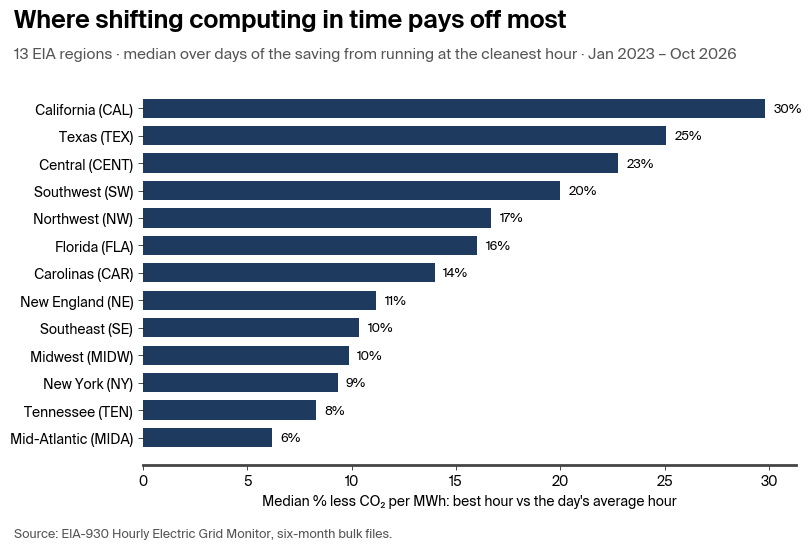

In [52]:
p = prize_region["best hour vs day average (% cleaner)"].sort_values()
fig, ax = plt.subplots(figsize=S.PANEL["L"])
ax.barh([f"{RN[r]} ({r})" for r in p.index], p.values, color=S.NAVY, height=0.7)
for i, v in enumerate(p.values):
    ax.text(v + 0.4, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("Median % less CO₂ per MWh: best hour vs the day's average hour")
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.spines["bottom"].set_linewidth(S.LINE_PT["profile"])
S.frame(fig, "Where shifting computing in time pays off most",
        "13 EIA regions · median over days of the saving from running at the cleanest hour · Jan 2023 – Oct 2026")
S.save(fig, f"{FIG}/05_scheduling_prize_by_region.png")

## 7. Summary of findings

**About the data**

- **Size and coverage:**
  - Raw: 2.28 GB of CSVs, 74 raw columns.
  - Grids: 69 balancing authorities in 13 regions, 4.3 million BA-hours.
  - Cleaned: one row per region × hour, **892,620 rows × 24 columns** (13 regions × 68,663 hours, Jan 2019 – Oct 2026). The focus period has 436,788 rows.
- **Quality is high after cleaning.** EIA's `(Adjusted)` columns replace the raw records that contain impossible values. Our cleaning removes one-hour spikes and out-of-range values per BA. Remaining problems are listed in Section 4, notably **California 2026 (verify)** and **Mid-Atlantic January 2020**.

**Full timeline (2019 – 2026)**

- **Regions differ by more than a factor of two.** Mean carbon intensity in 2025 ranges from 185 kg/MWh (California) and 214 (New York) to 474 (Midwest). Fossil fuels supply 42% to 77% of each region's power.
- **Most regions got cleaner, but not all.** Between 2019 and 2025:
  - Cleaner: Texas −24%, Northwest −22%, California −17%, Midwest −14%, Southeast −14%, Mid-Atlantic −10%.
  - Dirtier: New York +34%, New England +17%, Tennessee +8%.
- **Solar is the main change:** Texas grew from 1% to 14% of generation, the Southwest from 3% to 12%, and Florida from 1.5% to 9%.

**Focus period (2023 – Oct 2026)**

- **The cleanest hours are moving to midday.** In 12 of 13 regions, midday is cleaner than the day's average.
  - The share of days whose cleanest hour falls at 10:00–15:00 rose from 2023 to 2026: Texas 28% → 90%, Mid-Atlantic 17% → 71%, Midwest 6% → 61%.
  - **Central (SPP) is the exception:** it is cleanest at night on 78% of days, because of night-time wind.
- **The scheduling prize differs a lot by region.** Running at the day's best hour instead of an average hour cuts carbon intensity by a median of:
  - 6% in the Mid-Atlantic (PJM) and 8–10% in Tennessee, New York and the Midwest;
  - 20–30% in the Southwest, Central, Texas and California.
  - It is growing in most regions: Texas 20% → 30%, Northwest 13% → 22%, Florida 11% → 21% from 2023 to 2026.
- **Implications for modelling:**
  - Each region has its own daily shape, which is still changing year to year. A model should be fit per region (or use region as a feature), weight recent data, and be tested on the most recent months.
  - Because what matters is *which hours* are cleanest, evaluate the ranking of hours within a day, not just average error.

## 8. Notes for joining with the team's other ERCOT data

- **ERCOT = region `TEX`** (balancing authority `ERCO`, the only BA in that region). PJM = region `MIDA`.
- **Join key:** `utc_end` (end of hour, UTC). Convert the other source to UTC first. ERCOT's own reports use local **Central** time with "Hour Ending" 1–24 (and a repeated hour on the fall-back day). Here `hour` is the hour *beginning*: `hour ending 01:00 CPT` = `hour` 0.
- **Units:** MW averaged over the hour (= MWh in that hour); carbon intensity in kg CO₂/MWh (= g/kWh).
- **Fuel names:** ERCOT's categories (e.g. "Coal and Lignite", "Gas-CC") need mapping to `coal / gas / nuclear / solar / wind / hydro / other`. EIA-930 has no oil category for ERCOT.
- **Cross-check:** EIA-930 demand and generation for `TEX` should be very close to ERCOT's own published values. Comparing them hour by hour is a good first integration test.

**Data files in `data/`:**

| File | One row = |
|---|---|
| `regions_hourly_clean.csv.gz` | region × hour (the cleaned table above). `pd.read_csv` opens it directly |
| `region_flows_hourly.csv.gz` | region × neighbouring region × hour (MW, > 0 = export) |
| `balancing_authorities.csv` | one balancing authority: its region, first/last hour reported, hours reported per year |